# Fase 3 – Núcleo algorítmico, eficiencia y POO | TMDB
**MCDI500 – Grupo 4 · Avance Fase 3 – Semana 2**

**Alcance:** refactorizar y validar obtención, limpieza y transformación de TMDB. **No se implementa el recomendador final.**

**Objetivos:** demostrar ID 2.1 (funciones), ID 2.2 (complejidad), ID 2.3 (recursividad/división funcional), ID 3.1 (POO) e ID 3.2 (arquitectura). Cada salida se acompaña de interpretación calculada o criterio de lectura.

**Trazabilidad:** datos crudos y procesados de F2 aportados por el grupo. Las pruebas y mediciones se ejecutan nuevamente y no se presentan como resultados históricos de F2.

## 1. Configuración y reproducibilidad
Utilizar la estructura existente del repositorio `mcdi500-tmdb-grupo4`, identificando automáticamente su carpeta raíz para facilitar la importación de los módulos Python almacenados en `src/`. Registrar las versiones de Python y las bibliotecas utilizadas para garantizar la trazabilidad y reproducibilidad del entorno. La detección de dependencias ausentes se realiza sin interrumpir esta etapa de diagnóstico.

**Salida esperada:** ruta raíz del proyecto, versión de Python, ubicación del intérprete activo y versiones de las bibliotecas instaladas.

In [1]:
from pathlib import Path
import sys
import platform
from importlib.metadata import version, PackageNotFoundError

# Buscar la raíz del proyecto desde F3 o desde la raíz.
RAIZ = next(
    (
        ruta for ruta in [Path.cwd(), *Path.cwd().parents]
        if (ruta / "src" / "pipeline.py").is_file()
        and (ruta / "F3").is_dir()
    ),
    None
)

if RAIZ is None:
    raise FileNotFoundError(
        "No se encontró la raíz del proyecto. "
        "Verifica que existan las carpetas F3 y src."
    )

# Permitir importar módulos propios desde src.
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

print("=== CONFIGURACIÓN DEL ENTORNO ===")
print(f"Raíz del proyecto: {RAIZ}")
print(f"Python: {platform.python_version()}")
print(f"Intérprete: {sys.executable}")

print("\n=== VERSIONES DE LIBRERÍAS ===")

paquetes = [
    "pandas",
    "numpy",
    "scipy",
    "scikit-learn",
    "matplotlib",
    "pytest"
]

for paquete in paquetes:
    try:
        print(f"{paquete}: {version(paquete)}")
    except PackageNotFoundError:
        print(f"{paquete}: NO INSTALADO")


=== CONFIGURACIÓN DEL ENTORNO ===
Raíz del proyecto: <ruta local>\mcdi500-tmdb-grupo4
Python: 3.13.17
Intérprete: <ruta local>\mcdi500-tmdb-grupo4\venv\Scripts\python.exe

=== VERSIONES DE LIBRERÍAS ===
pandas: 3.1.1
numpy: 2.5.4
scipy: 1.18.1
scikit-learn: 1.9.1
matplotlib: 3.11.2
pytest: 9.2.0


La salida permite comprobar que el notebook utiliza el entorno de ejecución previsto y que los módulos del proyecto son accesibles. La identificación de bibliotecas no instaladas permite detectar posibles problemas de dependencias. Esta verificación constituye evidencia de reproducibilidad técnica, y no representa una evaluación de la calidad del dataset.

## 2. Carga y auditoría inicial del conjunto de datos

Se cargar el dataset original de películas TMDB (`movies_raw.csv`) y realizar una auditoría inicial para conocer su estructura, identificar posibles problemas de calidad y verificar que los datos sean adecuados para continuar con las etapas de limpieza y transformación.

**Justificación técnica:** antes de aplicar cualquier transformación, es necesario comprobar la integridad del conjunto de datos. Para ello, se examinan las siguientes características:

- **Dimensiones:** cantidad de registros (películas) y variables disponibles.
- **Tipos de datos:** verificar que cada columna tenga un tipo de dato compatible con su contenido, especialmente las variables numéricas.
- **Valores faltantes (NaN):** identificar las columnas que contienen datos ausentes y cuantificar su magnitud.
- **Identificadores duplicados:** verificar que cada película tenga un identificador `movie_id` único.
- **Integridad estructural:** comprobar que el dataset contenga las columnas requeridas para ejecutar correctamente el pipeline.

La **Decisión técnica** es implementar una carga de datos con validación explícita del esquema y conversión controlada de variables numéricas (*casting*). De esta manera, los valores no válidos se detectan mediante errores informativos, evitando que se conviertan silenciosamente en valores faltantes.

Adicionalmente, se carga el dataset procesado de Fase 2 como referencia para verificar la continuidad del proyecto. Es importante distinguir que algunos valores faltantes de las variables presupuesto e ingresos pueden corresponder a decisiones de limpieza previamente justificadas y no necesariamente a errores de procesamiento.

In [2]:
import pandas as pd, numpy as np
from src.carga import cargar
RAW = RAIZ/'data'/'raw'/'movies_raw.csv'
PROCESADO_F2 = RAIZ/'data'/'processed'/'movies_procesado.csv'
COLUMNAS=['movie_id','title','release_date','status','budget','revenue','runtime','genres','production_companies','production_countries','spoken_languages','original_language','vote_average','vote_count','popularity','adult']
NUMERICAS=['movie_id','budget','revenue','runtime','vote_average','vote_count','popularity']
df=cargar(str(RAW),COLUMNAS,NUMERICAS)
f2=pd.read_csv(PROCESADO_F2)
resumen=pd.DataFrame({'nulos':df.isna().sum(),'dtype':df.dtypes.astype(str)})
print('RAW:',df.shape,'| F2:',f2.shape,'| IDs duplicados RAW:',df.movie_id.duplicated().sum())
print(resumen.to_string())
assert df.movie_id.is_unique and len(df)>0
print('Interpretación:', 'esquema verificado; hay valores ausentes que deben tratarse por campo, no mediante eliminación indiscriminada.')

RAW: (17978, 16) | F2: (17978, 16) | IDs duplicados RAW: 0
                      nulos    dtype
movie_id                  0    int64
title                     0      str
release_date              0      str
status                    0      str
budget                    0    int64
revenue                   0    int64
runtime                   0    int64
genres                   10      str
production_companies    494      str
production_countries    176      str
spoken_languages         92      str
original_language         0      str
vote_average              0  float64
vote_count                0    int64
popularity                0  float64
adult                     0     bool
Interpretación: esquema verificado; hay valores ausentes que deben tratarse por campo, no mediante eliminación indiscriminada.


Este proceso la auditoría permite establecer un diagnóstico inicial de la calidad y estructura de los datos, identificando qué variables requieren tratamiento y cuáles pueden conservarse sin modificaciones. Esta información constituye el punto de partida para aplicar transformaciones controladas y verificar posteriormente su efecto sobre el dataset.

## 3. Verificación de integridad y continuidad de los datos entre Fase 2 y Fase 3

### Objetivo

Verificar que el conjunto de datos generado durante la Fase 2 (`movies_procesado.csv`) conserve la integridad de los registros originales de TMDB y contenga las variables procesadas necesarias para continuar con el desarrollo algorítmico de la Fase 3.

Esta comprobación permite establecer que el trabajo de esta fase utiliza datos provenientes de las etapas anteriores, manteniendo la continuidad y trazabilidad del proyecto.

### Justificación técnica

En la Fase 2 se realizaron operaciones de limpieza, tratamiento de valores faltantes, transformación de variables y generación de nuevas características para preparar el conjunto de datos.

Antes de incorporar nuevas implementaciones algorítmicas y aplicar programación orientada a objetos (POO), es necesario comprobar que el dataset procesado mantiene una estructura consistente respecto del dataset original.

Para ello, se realizan las siguientes verificaciones:

1. **Conservación de registros:** comprobar que ambos conjuntos contienen los mismos identificadores de películas (`movie_id`). Esto permite detectar pérdidas o incorporaciones de películas durante el procesamiento.

2. **Detección de duplicados:** verificar que no existan identificadores repetidos, filas completamente duplicadas o registros repetidos según la combinación de título y fecha de estreno.

3. **Identificación de títulos repetidos:** cuantificar las películas que comparten un título, considerando que pueden corresponder a producciones distintas, por ejemplo, nuevas versiones o películas estrenadas en años diferentes.

4. **Disponibilidad de variables procesadas:** comprobar que el dataset de Fase 2 contiene las características generadas durante la preparación, tales como `metadata_soup`, `weighted_rating`, `score_quality_norm` y `score_popularity_norm`.

### Decisión técnica

Utilizar el dataset original (`movies_raw.csv`) y el dataset procesado de Fase 2 (`movies_procesado.csv`) para comprobar la correspondencia de identificadores y verificar la disponibilidad de las variables derivadas.

Adicionalmente, se reutiliza la función `contar_duplicados()` del módulo `src.preparacion`. Esta decisión evita duplicar código y demuestra reutilización de funciones modulares, favoreciendo la mantenibilidad del proyecto.

La verificación se centra en la integridad de los registros y su estructura. No pretende demostrar que todas las transformaciones matemáticas de Fase 2 sean idénticas a las que se implementarán posteriormente en Fase 3.

Esta distinción es importante porque conservar los registros no garantiza, por sí solo, que todos los valores transformados sean correctos.

In [3]:
from src.preparacion import contar_duplicados, diccionario_procesado
requeridas={'metadata_soup','score_quality_norm','score_popularity_norm','weighted_rating'}
assert requeridas.issubset(f2.columns)
ids_iguales=set(df.movie_id)==set(f2.movie_id)
print('IDs compartidos:',ids_iguales,'| filas:',len(df),len(f2))
print(contar_duplicados(df).to_string())
print('Interpretación:', 'las claves '+('coinciden' if ids_iguales else 'difieren')+'; esto verifica cobertura de películas, no equivalencia total de atributos transformados.')

IDs compartidos: True | filas: 17978 17978
movie_id repetido                            0
filas completas repetidas                    0
título + fecha repetidos                     0
títulos repetidos (películas distintas)    656
Interpretación: las claves coinciden; esto verifica cobertura de películas, no equivalencia total de atributos transformados.


## 4. División del dataset en conjuntos de entrenamiento y prueba para validar el procesamiento de datos



El objetivo es dividir el conjunto de datos original de TMDB en dos subconjuntos independientes: uno de entrenamiento (80 %) y otro de prueba (20 %), con el propósito de comprobar que las funciones y transformaciones del pipeline se ejecutan correctamente sobre datos distintos de aquellos utilizados para calcular sus parámetros.

Esta división permitirá evaluar la capacidad del sistema de procesamiento para reutilizar las transformaciones aprendidas, sin recalcular sus parámetros a partir de nuevos datos.

### Justificación técnica

Algunas transformaciones utilizadas en la preparación de datos necesitan calcular parámetros estadísticos antes de modificar las variables.

Por ejemplo, el escalamiento MinMax transforma los valores de una variable mediante la siguiente expresión:


$X_{\text{norm}} = \frac{X - X_{\min}}{X_{\max} - X_{\min}}$.


Donde:

- $X$: valor original de la variable.
- $X_{\min}$: valor mínimo calculado durante el ajuste.
- $X_{\max}$: valor máximo calculado durante el ajuste.
- $X_{\text{norm}}$: valor transformado.

Para comprobar que el pipeline funciona correctamente, los valores mínimo y máximo deben calcularse utilizando únicamente los datos de entrenamiento.

Posteriormente, cuando se procese el conjunto de prueba, el sistema deberá reutilizar esos mismos parámetros, sin calcular otros nuevos.

Esta separación permite verificar una propiedad importante de los sistemas de procesamiento: **la independencia entre el aprendizaje de parámetros estadísticos y su aplicación posterior**.

Si utilizáramos todos los registros para calcular los parámetros antes de dividir los datos, estaríamos incorporando información del conjunto de prueba en el proceso de ajuste. Esta situación se conoce como *fuga de información* o *data leakage*.

Aunque en esta etapa no se está entrenando un modelo predictivo, aplicar esta separación permite demostrar que las transformaciones están implementadas correctamente y que el código puede procesar nuevos registros de manera consistente.

### Procedimiento

Se utilizará el conjunto original de TMDB, que contiene 17.978 películas, para realizar las siguientes operaciones:

1. **Definir una semilla aleatoria (`random_state=42`):** permite reproducir exactamente la misma selección de registros en diferentes ejecuciones.
2. **Seleccionar el 20 % de los registros para prueba:** mediante `sample(frac=0.20)`, se obtiene un subconjunto aleatorio de películas.
3. **Construir el conjunto de entrenamiento:** se excluyen del dataset original los registros seleccionados para prueba.
4. **Verificar la independencia de los subconjuntos:** se comprueba que ningún índice pertenezca simultáneamente a entrenamiento y prueba.
5. **Registrar las dimensiones resultantes:** se contabilizan las películas asignadas a cada subconjunto.

### Decisión técnica

Se utilizará una partición aleatoria del 80 % para entrenamiento y 20 % para prueba, manteniendo la semilla 42 para garantizar resultados reproducibles.

El conjunto de entrenamiento se utilizará para calcular los parámetros estadísticos que necesiten las transformaciones, mientras que el conjunto de prueba permitirá comprobar posteriormente que dichos parámetros se aplican sin recalcularse.

Esta decisión no tiene como finalidad medir precisión predictiva ni evaluar el desempeño de un recomendador. Su propósito es comprobar la correcta implementación del pipeline de preprocesamiento y su capacidad para transformar nuevos datos.

La separación también permitirá evaluar el comportamiento de los métodos `ajustar()` y `transformar()` que se desarrollan mediante programación orientada a objetos en las siguientes secciones.

In [4]:
SEMILLA=42
prueba=df.sample(frac=.20,random_state=SEMILLA)
entrenamiento=df.drop(prueba.index)
assert set(prueba.index).isdisjoint(entrenamiento.index)
print('Entrenamiento:',len(entrenamiento),'| Prueba:',len(prueba))
print('Interpretación: partición disjunta y reproducible; los parámetros de transformación no se aprenderán del conjunto de prueba.')

Entrenamiento: 14382 | Prueba: 3596
Interpretación: partición disjunta y reproducible; los parámetros de transformación no se aprenderán del conjunto de prueba.


El código anterior permitió dividir correctamente el conjunto de datos original de TMDB, compuesto por **17.978 películas**, en dos subconjuntos independientes:

- **Conjunto de entrenamiento:** 14.382 películas, equivalentes aproximadamente al 80 % del total.
- **Conjunto de prueba:** 3.596 películas, equivalentes aproximadamente al 20 % del total.

La suma de ambos subconjuntos corresponde al total de registros originales, por lo que no se evidencia pérdida de películas durante la partición.

**1. Independencia de los registros**

La instrucción `assert` comprueba que los índices de entrenamiento y prueba no tienen elementos en común.

Dado que la ejecución finalizó sin errores, se confirma que una misma fila del dataset original no fue asignada simultáneamente a ambos subconjuntos.

**2. Reproducibilidad de la partición**

La utilización de la semilla aleatoria `42` permite obtener la misma selección de registros cuando se ejecuta nuevamente el código sobre el mismo conjunto de datos y en las mismas condiciones.

Esto resulta importante para reproducir las pruebas del pipeline y comparar diferentes implementaciones bajo condiciones equivalentes.

**3. Función de cada subconjunto**

Los 14.382 registros de entrenamiento se utilizarán para calcular los parámetros estadísticos requeridos por las transformaciones, tales como valores mínimos y máximos.

Los 3.596 registros de prueba se reservarán para comprobar que esas transformaciones pueden aplicarse reutilizando los parámetros calculados durante el ajuste.

Es importante señalar que esta celda solamente demuestra la correcta separación de los registros. **Todavía no demuestra que el pipeline evite la fuga de información**, ya que ese comportamiento deberá verificarse al ejecutar los métodos `ajustar()` y `transformar()` en las siguientes etapas.

### Conclusión y decisión para continuar

La partición se realizó correctamente, conservando todos los registros del dataset y generando dos conjuntos sin superposición de índices.

Por consiguiente, se continua con la implementación y validación del pipeline orientado a objetos, utilizando el conjunto de entrenamiento para calcular los parámetros de transformación y el conjunto de prueba para comprobar su aplicación posterior.

Este procedimiento contribuye a establecer entradas claramente definidas y verificables para las operaciones de procesamiento posteriores.

## 5. Implementación de un pipeline de transformación de datos mediante Programación Orientada a Objetos


El objetivo es implementar un sistema modular de transformación de datos utilizando los principios de Programación Orientada a Objetos (POO), con el propósito de organizar, automatizar y reutilizar las operaciones de preprocesamiento realizadas sobre el conjunto de datos de películas TMDB.

El objetivo de esta etapa no es construir el recomendador de películas, sino **mejorar la arquitectura del código utilizado para preparar los datos**, reemplazando una secuencia de operaciones independientes por componentes especializados que puedan combinarse, mantenerse y ampliarse de manera controlada.

Adicionalmente, se busca verificar que el sistema sea capaz de procesar los conjuntos de entrenamiento y prueba utilizando las mismas transformaciones y los parámetros estadísticos calculados exclusivamente durante el ajuste con los datos de entrenamiento.

### Justificación técnica

Durante la Fase 2, las operaciones de limpieza y transformación se desarrollaron principalmente mediante funciones estructuradas de Python y herramientas de pandas.

Aunque esta aproximación permitió obtener los datos procesados, a medida que aumenta la cantidad de transformaciones también crece la necesidad de gestionar su orden de ejecución, los parámetros calculados, las validaciones y las dependencias entre operaciones.

Para abordar este problema, en Fase 3 se utiliza una arquitectura basada en dos componentes principales:

**1. Clase `Transformador` y sus clases derivadas**

Se establece una clase base denominada `Transformador`, que define una interfaz común para las operaciones de preprocesamiento:

- `ajustar()`: calcula y almacena los parámetros necesarios para una transformación.
- `transformar()`: aplica la transformación utilizando los parámetros previamente calculados.
- `ajustar_transformar()`: ejecuta ambas operaciones de manera consecutiva.

Las clases especializadas heredan de `Transformador` e implementan los métodos `aprender()` y `aplicar()` de acuerdo con la transformación correspondiente.

Esta organización permite incorporar distintos procedimientos de procesamiento sin modificar la interfaz general de utilización.

**2. Clase `Pipeline`**

La clase `Pipeline` se encarga de organizar y ejecutar los transformadores siguiendo una secuencia definida.

Su responsabilidad consiste en coordinar las operaciones, garantizar que se ejecuten en el orden establecido y reutilizar los parámetros aprendidos durante el ajuste.

De esta forma, el pipeline separa la coordinación del procesamiento de la lógica particular de cada transformación.

### Aplicación de los principios de POO

La arquitectura implementada incorpora los siguientes principios:

**Herencia:** los transformadores especializados heredan atributos y métodos de la clase base `Transformador`. Esto evita repetir código relacionado con la gestión del estado y la ejecución de transformaciones.

**Polimorfismo:** aunque cada transformador realiza una operación diferente, todos pueden utilizarse mediante una interfaz común. El pipeline ejecuta los métodos definidos sin necesitar conocer los detalles internos de cada clase.

**Encapsulamiento:** los parámetros aprendidos y el estado de ajuste se almacenan en atributos internos, como `_parametros` y `_ajustado`. Su acceso se controla mediante métodos y propiedades, siguiendo las convenciones de encapsulamiento de Python.

**Composición:** la clase `Pipeline` contiene objetos transformadores y coordina su ejecución. Esta relación permite construir diferentes secuencias de procesamiento combinando componentes reutilizables.

La utilización conjunta de estos principios favorece la modularidad, mantenibilidad y extensibilidad del sistema.

### Transformaciones que se implementarán

Para demostrar el funcionamiento de la arquitectura se construye un pipeline compuesto por cinco operaciones:

**Paso 1. Construcción de metadatos (`ConstructorSopa`)**

Combina información de géneros cinematográficos, productoras e idioma original para generar la columna `metadata_soup`.

Esta transformación permite representar atributos de contenido mediante un texto unificado, manteniendo la continuidad con las características preparadas en la Fase 2.

**Paso 2. Transformación logarítmica de popularidad (`LogNaturalPlus1`)**

Aplica la transformación matemática:

$X'=\ln(1+X)$

Su propósito es reducir la influencia de valores extremadamente elevados en una variable de distribución asimétrica positiva.

**Paso 3. Normalización MinMax de popularidad (`EscaladorMinMax`)**

Transforma la popularidad previamente ajustada con `log1p`, utilizando los valores mínimo y máximo calculados sobre el conjunto de entrenamiento.

**Paso 4. Normalización MinMax de valoración (`EscaladorMinMax`)**

Escala la variable `vote_average` para obtener valores comparables dentro de la escala definida a partir del conjunto de entrenamiento.

**Paso 5. Normalización MinMax de cantidad de votos (`EscaladorMinMax`)**

Aplica el mismo procedimiento a `vote_count`, conservando los parámetros obtenidos durante el ajuste.

Estas cinco operaciones se seleccionan para demostrar el funcionamiento del pipeline POO. No representan la totalidad de las transformaciones desarrolladas en Fase 2.

### Procedimiento de implementación

El código realizará las siguientes operaciones:

1. Importar la clase `Pipeline` y los transformadores correspondientes desde los módulos Python del proyecto.
2. Crear la función `construir_pipeline()`, encargada de definir los cinco pasos de procesamiento.
3. Instanciar el pipeline y ejecutar `ajustar()` utilizando exclusivamente las 14.382 películas del conjunto de entrenamiento.
4. Aplicar `transformar()` sobre entrenamiento y prueba, utilizando los parámetros aprendidos.
5. Generar un resumen que identifique el orden de las transformaciones y las clases responsables.
6. Comprobar las dimensiones de los conjuntos resultantes para verificar la conservación de los registros.

### Decisión técnica

Se utilizará una arquitectura basada en clases especializadas y composición de transformadores, evitando concentrar todas las operaciones de procesamiento en una única función extensa.

Los parámetros estadísticos se calcularán exclusivamente durante el ajuste con el conjunto de entrenamiento y posteriormente se reutilizarán para transformar los datos de prueba.

Esto permite mantener una separación entre el cálculo de parámetros y su aplicación, evitando que las estadísticas del conjunto de prueba influyan en el ajuste.

Asimismo, se conservarán las transformaciones originales de Fase 2 como referencia para las verificaciones posteriores, sin afirmar que este pipeline reproduce íntegramente todas las operaciones de la etapa anterior.

Esta implementación aporta evidencia de la utilización de los principios de la POO, mediante una arquitectura modular, documentada y extensible.

In [5]:
from src.pipeline import Pipeline
from src.transformadores import ConstructorSopa, LogNaturalPlus1, EscaladorMinMax

def construir_pipeline():
    return Pipeline([ConstructorSopa(),LogNaturalPlus1('popularity'),EscaladorMinMax('popularity'),EscaladorMinMax('vote_average'),EscaladorMinMax('vote_count')])
pipe=construir_pipeline().ajustar(entrenamiento)
train_t=pipe.transformar(entrenamiento)
test_t=pipe.transformar(prueba)
print(pipe.resumen().to_string(index=False))
print('Entrenamiento:',train_t.shape,'| prueba:',test_t.shape)
print('Interpretación: cinco pasos ejecutados sobre ambos subconjuntos, usando parámetros aprendidos exclusivamente del entrenamiento.')

 orden                           paso           clase
     1 ConstructorSopa(metadata_soup) ConstructorSopa
     2    LogNaturalPlus1(popularity) LogNaturalPlus1
     3    EscaladorMinMax(popularity) EscaladorMinMax
     4  EscaladorMinMax(vote_average) EscaladorMinMax
     5    EscaladorMinMax(vote_count) EscaladorMinMax
Entrenamiento: (14382, 17) | prueba: (3596, 17)
Interpretación: cinco pasos ejecutados sobre ambos subconjuntos, usando parámetros aprendidos exclusivamente del entrenamiento.


### Análisis e interpretación de la salida

La ejecución del pipeline orientado a objetos finalizó correctamente, permitiendo aplicar las cinco transformaciones configuradas a los conjuntos de entrenamiento y prueba.

**1. Verificación de la secuencia de procesamiento**

El resumen generado mediante `pipe.resumen()` muestra que las transformaciones se encuentran organizadas en el siguiente orden:

1. `ConstructorSopa(metadata_soup)`.
2. `LogNaturalPlus1(popularity)`.
3. `EscaladorMinMax(popularity)`.
4. `EscaladorMinMax(vote_average)`.
5. `EscaladorMinMax(vote_count)`.

Este orden es relevante porque existen dependencias entre las operaciones. En particular, la popularidad debe transformarse primero mediante `log1p` y posteriormente normalizarse.

El resultado evidencia que la arquitectura permite coordinar diferentes clases de transformación dentro de una misma secuencia de procesamiento.

**2. Conservación de los registros**

El conjunto de entrenamiento conserva sus **14.382 películas**, mientras que el conjunto de prueba mantiene sus **3.596 películas**.

Esto indica que las cinco transformaciones no eliminaron ni incorporaron registros durante el procesamiento.

**3. Generación de nuevas características**

Ambos conjuntos pasaron de 16 a 17 columnas.

Este incremento corresponde a la creación de `metadata_soup`, que integra información de géneros, productoras e idioma original.

Las transformaciones logarítmicas y de normalización modifican los valores de las columnas existentes, por lo que no incrementan el número de variables.

**4. Aplicación del enfoque orientado a objetos**

La utilización de un mismo pipeline para procesar ambos subconjuntos demuestra que los transformadores pueden organizarse y ejecutarse mediante una interfaz común.

En lugar de programar manualmente cada transformación para cada conjunto, se utiliza una única secuencia de objetos que encapsulan las operaciones correspondientes.

Esto reduce la duplicación de código y permite modificar o incorporar transformaciones sin reescribir toda la lógica de ejecución.

**5. Separación entre ajuste y transformación**

La ejecución utiliza `ajustar(entrenamiento)` para calcular los parámetros de los transformadores y luego aplica `transformar()` tanto sobre entrenamiento como sobre prueba.

El resultado es coherente con el diseño que busca reutilizar los parámetros aprendidos y evitar recalcularlos sobre los registros de prueba.

Sin embargo, para demostrar completamente que estos parámetros permanecen inalterados después de procesar el conjunto de prueba, es necesario comprobar sus valores antes y después de dicha operación. Esta validación corresponde a una etapa posterior.

### Conclusión y decisión para continuar

Los resultados demuestran que el pipeline orientado a objetos permite organizar y ejecutar correctamente cinco transformaciones sobre los datos de TMDB, conservando la cantidad de registros y generando la nueva característica `metadata_soup`.

La solución proporciona evidencia funcional de modularidad, composición de objetos y reutilización de una interfaz común, contribuyendo a los cumplimientos de los indicadores de la evaluación.

Se continuará con las pruebas de equivalencia y validación de parámetros para comprobar que la nueva arquitectura mantiene resultados coherentes respecto de las implementaciones estructuradas y que el procesamiento de los datos de prueba no modifica el estado aprendido.

## 6. Validación de las transformaciones y análisis de los rangos normalizados

### Objetivo

Verificar que las transformaciones numéricas implementadas mediante el pipeline orientado a objetos producen resultados coherentes con los parámetros estadísticos calculados durante el entrenamiento.

Para ello, se analizarán los valores mínimos y máximos de tres variables transformadas: `popularity`, `vote_average` y `vote_count`, comparando sus resultados en los conjuntos de entrenamiento y prueba.

Esta evaluación permitirá comprobar el comportamiento del escalamiento MinMax y determinar si las transformaciones mantienen criterios consistentes cuando reciben registros que no participaron en el cálculo de sus parámetros.

### Justificación técnica

En la sección anterior se implementó un pipeline compuesto por cinco transformaciones, entre ellas tres operaciones de normalización MinMax.

La normalización MinMax utiliza la siguiente expresión:

$X_{\text{norm}}=\frac{X-X_{\min}}{X_{\max}-X_{\min}}$

Los parámetros $X_{\min}$ y $X_{\max}$ se calculan exclusivamente sobre los datos de entrenamiento.

Como consecuencia, los valores del conjunto de entrenamiento normalmente quedan comprendidos entre 0 y 1, siempre que la variable tenga un rango distinto de cero y los datos sean válidos.

Sin embargo, cuando el mismo escalador se aplica a los datos de prueba, pueden aparecer valores superiores a 1 o inferiores a 0.

Esto sucede cuando un registro de prueba contiene un valor que supera el máximo o es inferior al mínimo utilizado durante el ajuste.

**Un valor normalizado fuera del intervalo [0, 1] no constituye necesariamente un error de procesamiento.** Puede indicar que el pipeline está aplicando correctamente los parámetros aprendidos, incluso cuando recibe valores que exceden los extremos observados en entrenamiento.

Por ejemplo, si durante el entrenamiento una variable presenta un mínimo de 10 y un máximo de 100, pero en prueba aparece un valor de 120, el resultado será:

$X_{\text{norm}}=\frac{120-10}{100-10}=1,2222$

El valor supera 1 porque el nuevo registro excede el máximo utilizado durante el ajuste.

Esta situación es diferente de recalcular el mínimo y máximo utilizando los datos de prueba. Hacerlo produciría una escala distinta y podría introducir fuga de información, afectando la consistencia del procesamiento.

### Variables que se analizarán

**1. `popularity` (popularidad de la película)**

En la sección anterior se aplicó primero una transformación logarítmica `log1p` para reducir la asimetría de la distribución y después un escalamiento MinMax.

Se verificará si los valores obtenidos mantienen el comportamiento esperado en entrenamiento y prueba.

**2. `vote_average` (calificación promedio)**

Esta variable representa la valoración promedio recibida por cada película.

Se comprobará si su normalización se ajusta a los extremos aprendidos durante el entrenamiento y si los registros de prueba permanecen dentro de ese intervalo.

**3. `vote_count` (cantidad de votos)**

Representa el número de votos recibidos por cada película.

Se analizará especialmente esta variable porque puede presentar diferencias importantes entre películas con pocos votos y producciones con un volumen elevado de valoraciones.

Si en prueba aparece una película con más votos que el máximo observado en entrenamiento, su valor normalizado puede superar 1.

### Procedimiento

El código realizará las siguientes operaciones:

1. Seleccionar las tres variables numéricas transformadas.
2. Calcular sus valores mínimos y máximos en entrenamiento.
3. Calcular sus valores mínimos y máximos en prueba.
4. Construir una tabla comparativa con los resultados.
5. Comprobar si alguna variable de prueba presenta valores fuera del intervalo [0, 1].
6. Informar qué variables requieren una interpretación adicional.

### Decisión técnica

Se conservarán los parámetros de normalización calculados durante el entrenamiento y se aplicarán sin modificaciones sobre los datos de prueba.

No se realizará un nuevo ajuste del escalador utilizando el conjunto de prueba, puesto que el propósito de esta evaluación es comprobar la reutilización de los parámetros y la consistencia del pipeline.

Los valores fuera del intervalo [0, 1] serán analizados como posibles consecuencias del procesamiento de nuevos datos, en lugar de corregirse automáticamente.

Esta decisión permite mantener la separación entre ajuste y transformación, favoreciendo la reproducibilidad y la robustez del sistema desarrollado mediante POO.

In [6]:
columnas=['popularity','vote_average','vote_count']
rangos=pd.DataFrame({'train_min':train_t[columnas].min(),'train_max':train_t[columnas].max(),'test_min':test_t[columnas].min(),'test_max':test_t[columnas].max()})
print(rangos.round(4).to_string())
for col,r in rangos.iterrows():
    fuera=bool(r.test_min<0 or r.test_max>1)
    print(f'Interpretación {col}:', 'prueba fuera de [0,1], compatible con ajuste exclusivo en entrenamiento.' if fuera else 'prueba dentro de [0,1] bajo los extremos aprendidos.')

              train_min  train_max  test_min  test_max
popularity          0.0        1.0    0.0069    0.9697
vote_average        0.0        1.0    0.0559    0.8701
vote_count          0.0        1.0    0.0000    1.0400
Interpretación popularity: prueba dentro de [0,1] bajo los extremos aprendidos.
Interpretación vote_average: prueba dentro de [0,1] bajo los extremos aprendidos.
Interpretación vote_count: prueba fuera de [0,1], compatible con ajuste exclusivo en entrenamiento.


### Análisis e interpretación de la salida

La auditoría permitió comparar los rangos de las variables numéricas transformadas, utilizando los conjuntos de entrenamiento y prueba procesados mediante el pipeline orientado a objetos.

Los resultados presentan diferencias que permiten evaluar el comportamiento del escalamiento y la reutilización de los parámetros calculados durante el ajuste.

**1. Verificación de la normalización del conjunto de entrenamiento**

Las tres variables analizadas (`popularity`, `vote_average` y `vote_count`) presentan valores mínimos de 0 y máximos de 1 en el conjunto de entrenamiento.

Esto confirma que el escalamiento MinMax produjo los rangos esperados para los datos utilizados durante el ajuste.

En consecuencia, existe evidencia de que los transformadores numéricos aplicaron correctamente la normalización sobre las variables evaluadas, al menos en términos de sus valores extremos.

Sin embargo, esta comprobación no demuestra por sí sola que cada valor individual haya sido transformado correctamente. Para verificarlo completamente, corresponde contrastar los resultados con la fórmula matemática y los parámetros almacenados por cada transformador.

**2. Análisis de la variable `popularity`**

En el conjunto de prueba, la popularidad normalizada presenta un mínimo de **0,0069** y un máximo de **0,9697**.

Ambos valores se encuentran dentro del intervalo [0, 1].

Esto significa que, para los registros de prueba evaluados, los valores de popularidad no excedieron los extremos utilizados por el escalador durante el entrenamiento.

Además, confirma que la transformación logarítmica y la normalización pudieron aplicarse a estos registros sin producir valores fuera del rango esperado.

**3. Análisis de la variable `vote_average`**

La calificación promedio normalizada presenta valores comprendidos entre **0,0559 y 0,8701** en el conjunto de prueba.

Este resultado indica que las calificaciones de las películas de prueba se encuentran dentro del rango de valores utilizado para ajustar el escalador.

Por consiguiente, no se detectan valores fuera del intervalo [0, 1] para esta variable.

**4. Análisis de la variable `vote_count`**

La cantidad de votos presenta un comportamiento diferente.

Mientras que el conjunto de entrenamiento registra valores normalizados entre 0 y 1, el conjunto de prueba alcanza un máximo de **1,0400**.

Esto significa que al menos una película del conjunto de prueba tiene una cantidad de votos superior al máximo utilizado para ajustar el escalador.

La diferencia de 0,0400 equivale a un **4 % del rango de entrenamiento**, expresado en la escala normalizada. No significa necesariamente que la película tenga un 4 % más de votos que la película con mayor cantidad de votos del conjunto de entrenamiento.

Este resultado es compatible con el funcionamiento esperado del escalamiento MinMax cuando se aplican parámetros previamente aprendidos a nuevos registros.

Por tanto, el valor 1,0400 no debe considerarse automáticamente un error ni corregirse mediante un nuevo ajuste sobre prueba.

**5. Evaluación de la consistencia del pipeline**

La comparación muestra que el pipeline puede aplicar sus transformaciones sobre registros de prueba cuyos valores no necesariamente coinciden con los extremos observados durante el entrenamiento.

La existencia de un valor superior a 1 en `vote_count` resulta compatible con la utilización de parámetros aprendidos exclusivamente sobre entrenamiento.

No obstante, los rangos observados no constituyen por sí solos una prueba completa de ausencia de fuga de información. Para acreditarla, se debe comprobar que los parámetros almacenados antes y después de transformar el conjunto de prueba permanecen inalterados.

### Conclusión y decisión para continuar

Los resultados permiten establecer que las tres variables numéricas fueron normalizadas correctamente en el conjunto de entrenamiento, obteniéndose mínimos de 0 y máximos de 1.

En el conjunto de prueba, `popularity` y `vote_average` permanecen dentro del intervalo [0, 1], mientras que `vote_count` alcanza un máximo de 1,0400, comportamiento compatible con la aplicación de parámetros aprendidos sobre datos diferentes.

**Se decide conservar las transformaciones realizadas y no recalcular los parámetros utilizando el conjunto de prueba.**

La auditoría entrega evidencia de consistencia en el procesamiento y permite avanzar hacia las pruebas de equivalencia, robustez y control del estado de los transformadores.

Esta sección contribuye a verificar la coherencia de los resultados del procesamiento, y  examinar el comportamiento de los transformadores implementados mediante POO.

## 7. Verificación de equivalencia entre programación estructurada y programación orientada a objetos (ID 2.1 e ID 3.1)

### Objetivo

Comprobar que las transformaciones de datos implementadas mediante programación orientada a objetos (POO) producen resultados equivalentes a los obtenidos mediante una implementación estructurada de las mismas operaciones.

El propósito de esta evaluación es verificar que la reorganización del código en clases, métodos y objetos no modifica los resultados del procesamiento de datos.

Esta comprobación es relevante porque la Fase 3 busca mejorar la arquitectura, modularidad y mantenibilidad del sistema desarrollado en las etapas anteriores, conservando la coherencia funcional de las transformaciones existentes.

### Justificación técnica

Durante la Fase 2, el procesamiento de los datos de TMDB se desarrolló principalmente mediante funciones y operaciones estructuradas de Python y pandas.

En la Fase 3, parte de ese procesamiento se reorganizó utilizando una arquitectura orientada a objetos, compuesta por una clase `Pipeline` y diferentes clases transformadoras.

Aunque ambas aproximaciones permiten ejecutar operaciones similares, presentan diferencias en su organización:

**Programación estructurada**

Las transformaciones se ejecutan mediante instrucciones y funciones organizadas secuencialmente. El programador controla directamente el orden de las operaciones, los cálculos y las variables utilizadas.

**Programación orientada a objetos**

Las transformaciones se encapsulan en objetos especializados, que poseen métodos para calcular sus parámetros y aplicar las operaciones correspondientes.

La clase `Pipeline` coordina la ejecución de esos objetos, permitiendo reutilizar las transformaciones mediante una interfaz común.

Desde el punto de vista del resultado, ambas implementaciones deberían producir valores equivalentes cuando utilizan:

- El mismo conjunto de datos.
- Las mismas operaciones.
- El mismo orden de procesamiento.
- Los mismos criterios de cálculo de parámetros.

Por tanto, **la implementación POO no se considera correcta únicamente porque esté organizada en clases**. También debe demostrar que conserva el comportamiento esperado de las transformaciones.

Esta prueba permite verificar la corrección funcional de la refactorización, es decir, de la reorganización interna del código sin modificar intencionalmente su resultado.

### Transformaciones que se compararán

La comparación contempla cinco operaciones implementadas previamente:

**1. Construcción de `metadata_soup`**

Se genera una representación textual combinando géneros cinematográficos, productoras e idioma original.

Se comprobará que ambas implementaciones producen exactamente las mismas cadenas de texto.

**2. Transformación logarítmica de `popularity`**

Se aplica la función `np.log1p()` sobre la popularidad de las películas.

Se verificará que los resultados numéricos sean equivalentes.

**3. Normalización MinMax de `popularity`**

Se normaliza la popularidad transformada mediante los valores mínimo y máximo del conjunto de entrenamiento.

**4. Normalización MinMax de `vote_average`**

Se escala la calificación promedio de las películas utilizando sus extremos observados en entrenamiento.

**5. Normalización MinMax de `vote_count`**

Se transforma la cantidad de votos mediante el mismo procedimiento.

Es importante establecer que estas cinco operaciones corresponden a una parte del procesamiento utilizado en el proyecto y no representan la totalidad de las transformaciones de Fase 2.

### Procedimiento de validación

Para efectuar la comparación, el código realizará las siguientes operaciones:

1. Crear una copia independiente del conjunto de entrenamiento original, evitando modificar directamente los datos de entrada.
2. Aplicar las cinco transformaciones mediante una secuencia estructurada de instrucciones Python.
3. Utilizar el resultado previamente generado mediante el pipeline orientado a objetos.
4. Seleccionar las mismas columnas en ambas implementaciones y ordenarlas de forma consistente para evitar diferencias atribuibles únicamente a su posición.
5. Comparar los valores mediante la función `assert_frame_equal()` de pandas.
6. Verificar que los resultados numéricos sean equivalentes dentro de una tolerancia definida y que las transformaciones textuales coincidan.

### Criterio de validación

Se utiliza `assert_frame_equal()` con los siguientes parámetros:

- `check_exact=False`: permite comparar valores numéricos considerando pequeñas diferencias de precisión.
- `rtol=1e-10`: establece una tolerancia relativa para la comparación numérica.
- `atol=1e-12`: establece una tolerancia absoluta para diferencias numéricas muy pequeñas.

Estas tolerancias permiten aceptar diferencias insignificantes atribuibles a la representación de números de punto flotante, sin admitir discrepancias relevantes en los resultados.

Para las columnas de texto, la comparación requiere coincidencia exacta de sus valores.

Si las implementaciones presentan diferencias que superan las condiciones establecidas, la comprobación genera un error, indicando que los resultados no son equivalentes.

### Decisión técnica

Se establece la implementación estructurada como referencia funcional para verificar la versión orientada a objetos.

Esta comparación permitirá determinar si la nueva arquitectura conserva los resultados esperados y si la reorganización del procesamiento puede continuar sin introducir diferencias funcionales no justificadas.

La equivalencia se evaluará exclusivamente sobre las cinco transformaciones implementadas en esta sección, sin afirmar que se ha reproducido de forma íntegra el pipeline original de Fase 2.

Este procedimiento contribuye a verificar la coherencia entre entradas, procesamiento y resultados, y comprobar el funcionamiento de una implementación modular orientada a objetos.

In [7]:
from pandas.testing import assert_frame_equal
from src.transformadores import ConstructorSopa as CS
base=entrenamiento.copy()
base=CS().ajustar_transformar(base)
base['popularity']=np.log1p(base['popularity'])
for col in columnas:
    minimo=base[col].min(); rango=base[col].max()-minimo
    base[col]=(base[col]-minimo)/(rango if rango else 1.)
assert_frame_equal(base[train_t.columns].sort_index(axis=1),train_t.sort_index(axis=1),check_exact=False,rtol=1e-10,atol=1e-12)
print('Equivalencia parcial estructurada/POO: APROBADA')
print('Interpretación: ambas versiones reproducen los cinco pasos evaluados; no prueba igualdad del pipeline F2 completo.')

Equivalencia parcial estructurada/POO: APROBADA
Interpretación: ambas versiones reproducen los cinco pasos evaluados; no prueba igualdad del pipeline F2 completo.


### Análisis e interpretación de la salida

La comparación entre la implementación estructurada y el pipeline orientado a objetos finalizó correctamente, obteniéndose el mensaje:

**«Equivalencia parcial estructurada/POO: APROBADA».**

Este resultado significa que ambas implementaciones produjeron valores equivalentes para las cinco operaciones de transformación evaluadas.

**1. Correspondencia de las transformaciones textuales**

La columna `metadata_soup` generada mediante la implementación estructurada coincide con la obtenida mediante el transformador orientado a objetos.

Esto evidencia que la reorganización del código no modificó la representación textual de los metadatos dentro del conjunto de entrenamiento evaluado.

**2. Correspondencia de las transformaciones numéricas**

Las variables `popularity`, `vote_average` y `vote_count` presentan resultados numéricos equivalentes entre ambas implementaciones, considerando las tolerancias establecidas.

Esto permite verificar que la aplicación de la transformación logarítmica y los escaladores MinMax mantiene resultados consistentes entre los dos enfoques de programación.

**3. Validación funcional de la arquitectura POO**

La prueba demuestra que las clases y métodos utilizados por el pipeline pueden reproducir el comportamiento de las operaciones estructuradas de referencia.

Por tanto, la reorganización del código mediante objetos no introdujo diferencias detectables en las transformaciones evaluadas.

Este resultado respalda la utilización de una arquitectura modular, ya que permite mejorar la organización del código conservando su comportamiento funcional.

**4. Alcance de la equivalencia comprobada**

Es importante precisar que la prueba se realizó sobre el conjunto de entrenamiento y las cinco transformaciones seleccionadas.

Por consiguiente, el resultado no demuestra que se hayan reproducido todas las operaciones originales de la Fase 2 ni verifica por sí solo la aplicación correcta del pipeline sobre los datos de prueba.

Tampoco permite establecer que la implementación orientada a objetos sea más eficiente en tiempo o memoria.

La equivalencia funcional y la eficiencia computacional corresponden a propiedades diferentes que deben evaluarse mediante procedimientos específicos.

### Conclusión y decisión para continuar

Los resultados permiten concluir que las implementaciones estructurada y orientada a objetos producen valores equivalentes para las transformaciones analizadas.

En consecuencia, **se considera validada la equivalencia funcional de los cinco pasos evaluados sobre los datos de entrenamiento**, lo que respalda la continuidad de la arquitectura POO propuesta para la Fase 3.

La siguiente etapa deberá ampliar la validación mediante pruebas de casos normales, condiciones límite y manejo de excepciones, para comprobar la robustez de los componentes implementados.

Posteriormente, las mediciones de complejidad temporal y espacial permitirán evaluar la eficiencia de las soluciones, complementando la evidencia de corrección funcional obtenida en esta sección.

Esta comprobación constituye evidencia de cumplimiento para los indicadores **ID 2.1 e ID 3.1**, al verificar la coherencia del procesamiento y el funcionamiento de componentes orientados a objetos.

## 8. Aplicación de recursividad en el procesamiento de metadatos cinematográficos 

### Objetivo

Implementar y verificar un algoritmo recursivo capaz de procesar estructuras de metadatos organizadas en listas anidadas, transformándolas en una lista plana de elementos.

Para comprobar su funcionamiento, se desarrollan y comparan dos soluciones:

- **Implementación recursiva:** utiliza una función que se llama a sí misma para procesar los elementos de una estructura anidada.
- **Implementación iterativa:** realiza el mismo procesamiento mediante estructuras de control y una pila explícita.

La finalidad es demostrar que ambas implementaciones pueden resolver el mismo problema, analizar sus diferencias algorítmicas y verificar que producen resultados equivalentes.

Esta actividad permite aplicar programación estructurada y recursiva a un problema relacionado con la preparación de metadatos, contribuyendo al desarrollo de módulos reutilizables y verificables.

### Justificación técnica: ¿por qué utilizar recursividad?

En el procesamiento de datos, es posible encontrar información organizada mediante estructuras jerárquicas, como listas que contienen otras listas.

Este tipo de representación es habitual en estructuras JSON utilizadas para intercambiar información entre sistemas y servicios.

Por ejemplo, los metadatos cinematográficos podrían organizarse de la siguiente manera:

```python
[
    "Drama",
    ["Thriller", ["Romance"]],
    None,
    ["Comedy"]
]
```

La estructura contiene distintos niveles de profundidad:

- `Drama` se encuentra en el nivel principal.
- `Thriller` está dentro de una lista secundaria.
- `Romance` está dentro de una lista anidada a mayor profundidad.
- `None` representa un elemento sin valor.
- `Comedy` pertenece a otra lista secundaria.

Si se desea utilizar estos metadatos en una transformación posterior, puede ser necesario convertirlos en una secuencia lineal de elementos.

El resultado esperado sería:

```python
["Drama", "Thriller", "Romance", "Comedy"]
```

Este procedimiento se denomina **aplanamiento de estructuras anidadas** (*flattening*).

La recursividad constituye una alternativa apropiada porque permite resolver una estructura compleja mediante la aplicación repetida de una misma operación sobre sus componentes.

Cada vez que el algoritmo encuentra una lista dentro de otra lista, vuelve a ejecutar la misma función para procesar sus elementos.

### Fundamento de la solución recursiva

Un algoritmo recursivo se caracteriza por disponer de dos componentes fundamentales:

**1. Caso base**

Representa la condición que permite finalizar una llamada recursiva.

En este ejercicio, cuando se encuentra un elemento individual que no requiere recorrer otra lista, se procesa directamente. Los valores nulos se descartan de acuerdo con las reglas de limpieza establecidas.

**2. Caso recursivo**

Se presenta cuando el algoritmo encuentra una lista anidada.

En ese caso, la función vuelve a llamarse para procesar el contenido de esa lista, repitiendo el procedimiento hasta alcanzar elementos individuales.

El resultado de cada llamada se incorpora a la lista final, conservando el orden de aparición.

### Fundamento de la solución iterativa

Como alternativa, se implementa un algoritmo iterativo utilizando una pila explícita.

La pila permite almacenar temporalmente los elementos pendientes de procesamiento y recorrer las listas anidadas sin realizar llamadas recursivas.

Esta solución puede representar una ventaja cuando existen estructuras con niveles elevados de anidamiento, porque evita depender directamente de la profundidad máxima de recursión permitida por Python.

Sin embargo, la implementación requiere administrar explícitamente los elementos pendientes y mantener el orden correcto de procesamiento.

### Procedimiento de evaluación

Para verificar el funcionamiento de ambas implementaciones, se realizarán las siguientes operaciones:

1. Definir una estructura de ejemplo que contenga metadatos cinematográficos organizados en diferentes niveles de anidamiento.
2. Ejecutar la función `aplanar_recursivo()` sobre dicha estructura.
3. Ejecutar la función `aplanar_iterativo()` utilizando exactamente los mismos datos.
4. Mostrar los resultados de ambas implementaciones.
5. Comparar los resultados mediante una aserción (`assert`) para comprobar su equivalencia.
6. Verificar que se conserva el orden de los elementos y que los valores nulos son tratados de acuerdo con las reglas definidas.

### Decisión técnica

Se utilizará una estructura de metadatos simulada para demostrar el funcionamiento de las implementaciones recursiva e iterativa.

Esta decisión se fundamenta en que el dataset TMDB utilizado en el proyecto representa actualmente los géneros y las productoras mediante cadenas de texto separadas por el carácter `|`, y no mediante listas anidadas.

Por consiguiente, el ejercicio no pretende afirmar que el dataset original contiene este tipo de estructuras. Su propósito es demostrar cómo podría procesarse una representación jerárquica de metadatos si fuera incorporada en una etapa posterior de obtención de datos.

Ambas implementaciones se evaluarán inicialmente en términos de corrección funcional. Posteriormente, sus características de complejidad temporal y espacial permitirán analizar las ventajas y limitaciones de cada enfoque.

Esta implementación contribuye a aplicar recursividad, estructuras de control y división de problemas en módulos reutilizables.

In [8]:
from src.recursividad import aplanar_recursivo, aplanar_iterativo
caso=['Drama',['Thriller',['Romance']],None,('Comedy',)]
a=aplanar_recursivo(caso); b=aplanar_iterativo(caso)
assert a==b
print('Recursivo:',a,'| iterativo:',b)
print('Interpretación: ambos métodos preservan orden y tokens; el límite de profundidad controla el riesgo de recursión excesiva.')

Recursivo: ['Drama', 'Thriller', 'Romance', 'Comedy'] | iterativo: ['Drama', 'Thriller', 'Romance', 'Comedy']
Interpretación: ambos métodos preservan orden y tokens; el límite de profundidad controla el riesgo de recursión excesiva.


### Análisis e interpretación de la salida

La ejecución permitió procesar correctamente una estructura de metadatos cinematográficos que contenía listas anidadas y un valor nulo.

Los algoritmos recursivo e iterativo generaron el mismo resultado:

`['Drama', 'Thriller', 'Romance', 'Comedy']`

A continuación, se analizan los resultados obtenidos.

**1. Funcionamiento de la implementación recursiva**

La función `aplanar_recursivo()` logró recorrer la estructura original, identificando los elementos contenidos en diferentes niveles de anidamiento.

El resultado demuestra que el algoritmo pudo extraer los valores individuales y reunirlos en una lista lineal, sin conservar la estructura jerárquica original.

En particular, el elemento `Romance`, ubicado dentro de una lista anidada en un segundo nivel, fue recuperado correctamente.

Esto constituye evidencia del funcionamiento de la recursividad, ya que el procesamiento requiere resolver estructuras internas mediante llamadas sucesivas a la misma función.

**2. Funcionamiento de la implementación iterativa**

La función `aplanar_iterativo()` produjo exactamente la misma lista de elementos.

En este caso, el recorrido se realiza mediante una pila explícita, permitiendo administrar los elementos pendientes de procesamiento sin depender de llamadas recursivas.

El resultado demuestra que la recursividad no es la única estrategia para resolver este problema y que una solución basada en estructuras de control también puede obtener el mismo resultado.

**3. Conservación del orden de los metadatos**

Ambas implementaciones conservaron la secuencia original de aparición de los elementos:

`Drama → Thriller → Romance → Comedy`

Esto resulta relevante porque la transformación no debe alterar arbitrariamente el orden de los elementos cuando se busca preservar la estructura lógica de los datos originales.

**4. Tratamiento de valores nulos**

La estructura original incluía un elemento `None`, que no aparece en el resultado final.

Esto indica que ambas implementaciones aplicaron la regla de omisión de valores nulos definida para el ejercicio.

De esta forma, se obtiene una lista compuesta únicamente por los metadatos válidos del caso evaluado.

**5. Comprobación de equivalencia funcional**

La instrucción `assert a == b` se ejecutó sin generar errores.

Esto confirma que ambas implementaciones produjeron exactamente la misma secuencia de elementos para el caso de prueba utilizado.

La equivalencia funcional constituye una condición necesaria para comparar posteriormente el rendimiento de las soluciones, ya que permite evaluar diferentes implementaciones que resuelven el mismo problema.

Sin embargo, esta comprobación corresponde únicamente al ejemplo ejecutado. Para establecer una mayor robustez, sería necesario evaluar estructuras vacías, listas profundamente anidadas, valores nulos y combinaciones adicionales de elementos.

### Análisis de complejidad algorítmica

Sea \(N\) el número total de elementos y sublistas que debe visitar el algoritmo, y \(h\) la profundidad máxima de anidamiento.

**Implementación recursiva**

- **Complejidad temporal:** O(N), bajo el supuesto de que cada elemento y sublista se procesa una sola vez.
- **Complejidad espacial:** O(N + h), considerando la lista resultante y la memoria asociada a las llamadas recursivas.

**Implementación iterativa**

- **Complejidad temporal:** O(N), si cada elemento se procesa una vez y las operaciones sobre la pila tienen costo constante amortizado.
- **Complejidad espacial:** O(N + p), considerando la lista resultante y los elementos pendientes almacenados en la pila, donde \(p\) representa el máximo tamaño de la pila explícita.

Ambas implementaciones presentan complejidad temporal lineal respecto del tamaño de la estructura procesada.

La principal diferencia se relaciona con la administración de memoria. La solución recursiva utiliza la pila de llamadas de Python, mientras que la iterativa administra una pila de datos explícita.

### Conclusión y decisión para continuar

Los resultados permiten concluir que las implementaciones recursiva e iterativa resuelven correctamente el caso de aplanamiento de metadatos evaluado, conservando el orden de los elementos y omitiendo el valor nulo.

La comparación demuestra equivalencia funcional para el ejemplo ejecutado y permite identificar dos estrategias algorítmicas diferentes para abordar una misma operación de procesamiento.

**Se decide conservar ambas implementaciones con fines de comparación y validación**, considerando que la solución iterativa puede ser preferible cuando se requiere procesar estructuras con niveles de anidamiento elevados.

No obstante, todavía no es posible afirmar cuál implementación es más rápida o consume menos memoria en la práctica, ya que esos aspectos requieren mediciones experimentales reproducibles.


## 9. Validación de robustez del código mediante pruebas funcionales, casos límite y manejo de excepciones (ID 2.1 e ID 3.1)

### Objetivo

Evaluar la robustez de los componentes algorítmicos desarrollados en Fase 3, verificando que las funciones y clases del sistema respondan correctamente tanto a condiciones normales de ejecución como a situaciones que representan un uso incorrecto o exceden las restricciones establecidas.

Para ello, se realizarán pruebas controladas sobre el pipeline orientado a objetos, los transformadores y el algoritmo recursivo, comprobando que las entradas inválidas sean detectadas y que el sistema genere las excepciones correspondientes.

La finalidad es demostrar que el código incorpora mecanismos de validación y control de errores que contribuyen a su confiabilidad, mantenibilidad y reutilización.

### Justificación técnica

En el desarrollo de software, una ejecución exitosa no demuestra por sí sola que un programa sea robusto.

Por ejemplo, un pipeline puede funcionar correctamente cuando recibe un DataFrame con todas las columnas necesarias y cuando sus transformadores han sido ajustados previamente. Sin embargo, podría comportarse incorrectamente si recibe una columna con valores de tipos inesperados o si se intenta aplicar una transformación antes de calcular sus parámetros.

De manera similar, un algoritmo recursivo puede procesar estructuras anidadas válidas, pero necesita controlar situaciones que excedan las restricciones de profundidad establecidas.

Si estas condiciones no se validan, pueden producirse resultados incorrectos o errores difíciles de identificar.

Para reducir estos riesgos, se incorporan mecanismos de verificación que permiten identificar entradas no válidas y generar excepciones informativas.

En esta sección se distinguen tres categorías de pruebas:

**1. Pruebas de funcionamiento normal**

Comprueban que los componentes generan resultados correctos cuando reciben datos válidos y se utilizan conforme a sus condiciones de funcionamiento.

Estas pruebas permiten verificar el comportamiento esperado de las funciones y métodos del sistema.

**2. Pruebas de casos límite**

Evalúan situaciones ubicadas en los extremos de las condiciones permitidas, como estructuras vacías o límites de profundidad en funciones recursivas.

Su propósito es identificar posibles defectos que no necesariamente aparecen durante una ejecución habitual.

**3. Pruebas de excepciones**

Comprueban que el software detecta situaciones no permitidas y genera el tipo de error esperado, en lugar de continuar con un procesamiento incorrecto.

Estas pruebas son importantes para verificar que los componentes respeten las restricciones definidas en su implementación.

### Pruebas que se ejecutarán

La implementación presentada contempla tres escenarios específicos.

**Prueba 1. Intento de transformación sin ajuste previo**

La clase `Pipeline` requiere ejecutar `ajustar()` antes de utilizar `transformar()`.

Durante el ajuste, los transformadores calculan los parámetros estadísticos necesarios, como valores mínimos y máximos.

Si se intenta transformar información antes de realizar ese procedimiento, el pipeline no dispone de un estado válido para ejecutar correctamente todas las operaciones.

Se comprobará que esta situación genere una excepción `RuntimeError`.

Esta prueba permite evaluar el control del estado interno de los objetos, relacionado con el principio de encapsulamiento.

**Prueba 2. Procesamiento de metadatos con tipos de datos incorrectos**

El transformador `ConstructorSopa` procesa metadatos textuales correspondientes a géneros, productoras e idioma original.

Para ello, se espera que las columnas utilizadas contengan valores compatibles con las operaciones de texto implementadas.

Se introducirá deliberadamente un número entero en la columna `genres` para comprobar que el transformador detecte esta condición y genere una excepción `TypeError`.

La finalidad es verificar que el sistema no procese silenciosamente información incompatible con la transformación solicitada.

**Prueba 3. Control de profundidad en el algoritmo recursivo**

El algoritmo `aplanar_recursivo()` procesa listas anidadas mediante llamadas sucesivas a una misma función.

Sin embargo, una estructura con demasiados niveles de anidamiento puede incrementar el consumo de memoria asociado a la pila de llamadas y superar los límites permitidos por Python.

Para controlar esta situación, la implementación incorpora el parámetro `max_profundidad`, que establece el nivel máximo permitido para el procesamiento.

Se utilizará una estructura anidada y un límite de profundidad igual a cero para comprobar que el algoritmo rechaza la operación mediante una excepción `ValueError`.

Esta prueba permite verificar que el procedimiento recursivo incorpora un mecanismo de control frente a condiciones no permitidas.

### Procedimiento de validación

El código ejecutará los siguientes pasos:

1. Importar las funciones y clases necesarias para realizar las pruebas.
2. Definir una función auxiliar denominada `comprobar()`, encargada de ejecutar cada escenario y capturar la excepción esperada.
3. Intentar ejecutar el pipeline sin realizar previamente el ajuste.
4. Introducir un valor de tipo incorrecto en los metadatos y ejecutar el transformador correspondiente.
5. Ejecutar el algoritmo recursivo utilizando un límite de profundidad que impida procesar la estructura.
6. Registrar el resultado de cada prueba en una tabla.
7. Verificar mediante una aserción que las tres pruebas hayan generado las excepciones esperadas.

### Decisión técnica

Se implementarán pruebas controladas que provoquen deliberadamente condiciones de error, con el objetivo de verificar que los componentes desarrollados respondan de forma predecible.

Las excepciones esperadas se consideran resultados satisfactorios cuando corresponden al comportamiento definido para cada función o clase.

Por lo tanto, en este contexto, **una prueba que genera la excepción correcta se considera aprobada**, porque demuestra que el programa reconoce y rechaza una operación no permitida.

Esta estrategia permite evaluar aspectos de robustez asociados al control del estado de los objetos, la validación de tipos de datos y la protección de los algoritmos recursivos.

In [9]:
import pytest
from src.recursividad import aplanar_recursivo
casos=[]
def comprobar(nombre,funcion,error):
    try:funcion();casos.append((nombre,'FALLO: no rechazó entrada'))
    except error:casos.append((nombre,'OK: excepción esperada'))
comprobar('transformar sin ajustar',lambda: construir_pipeline().transformar(df.iloc[:2]),RuntimeError)
comprobar('metadato inválido',lambda: ConstructorSopa().ajustar_transformar(df.iloc[:2].assign(genres=123)),TypeError)
comprobar('profundidad recursiva',lambda: aplanar_recursivo([['x']],max_profundidad=0),ValueError)
print(pd.DataFrame(casos,columns=['caso','resultado']).to_string(index=False))
assert all(x[1].startswith('OK') for x in casos)
print('Interpretación: controles de estado, tipo y profundidad rechazan entradas impropias con excepciones explícitas.')

                   caso              resultado
transformar sin ajustar OK: excepción esperada
      metadato inválido OK: excepción esperada
  profundidad recursiva OK: excepción esperada
Interpretación: controles de estado, tipo y profundidad rechazan entradas impropias con excepciones explícitas.


### Análisis e interpretación de los resultados

La ejecución de las pruebas de robustez permitió evaluar tres situaciones de uso incorrecto o condiciones restringidas del sistema.

Los resultados muestran que las tres pruebas finalizaron correctamente, generando las excepciones esperadas para cada escenario.

**1. Validación del estado del pipeline**

La prueba denominada `transformar sin ajustar` obtuvo el resultado:

**OK: excepción esperada.**

Esto significa que el pipeline detectó el intento de ejecutar el método `transformar()` antes de haber realizado el ajuste correspondiente.

La excepción `RuntimeError` confirma que el sistema incorpora un mecanismo para impedir la transformación de datos cuando los parámetros necesarios todavía no han sido calculados.

Este comportamiento es importante porque evita utilizar transformadores en un estado no válido y contribuye al control de las operaciones mediante los métodos definidos en las clases.

Por lo tanto, la prueba entrega evidencia favorable respecto de la gestión del estado interno y la robustez del pipeline orientado a objetos.

**2. Validación de tipos de datos en metadatos**

La prueba `metadato inválido` también obtuvo el resultado:

**OK: excepción esperada.**

En este escenario se introdujo deliberadamente un valor entero en un campo que el transformador procesa mediante operaciones de texto.

La generación de la excepción `TypeError` demuestra que la operación no aceptó el valor incompatible con el procesamiento solicitado.

Este resultado confirma que, para el caso evaluado, el transformador no continuó silenciosamente con una entrada de tipo incorrecto.

No obstante, la prueba no demuestra una validación exhaustiva de todos los tipos de datos posibles. Para ello sería necesario comprobar otros escenarios, como valores nulos, listas, diccionarios o columnas completas con tipos incompatibles.

**3. Control de profundidad del algoritmo recursivo**

La prueba `profundidad recursiva` obtuvo el resultado:

**OK: excepción esperada.**

La ejecución utilizó una estructura anidada junto con un límite de profundidad que impedía completar su procesamiento.

La excepción `ValueError` evidencia que la función identificó la condición no permitida y detuvo la operación.

Este comportamiento demuestra que el algoritmo recursivo dispone de un mecanismo para controlar la profundidad máxima autorizada.

La utilización de este límite permite establecer restricciones explícitas sobre el procesamiento de estructuras jerárquicas y reducir el riesgo de ejecutar recursiones excesivamente profundas.

**4. Resultado global de las pruebas**

Las tres pruebas generaron las excepciones previstas:

- `RuntimeError`: control del estado del pipeline.
- `TypeError`: rechazo de metadatos incompatibles.
- `ValueError`: control de profundidad del algoritmo recursivo.

Adicionalmente, la aserción final se ejecutó sin errores, confirmando que los tres escenarios fueron registrados como aprobados.

Este resultado demuestra que los componentes evaluados incorporan controles funcionales frente a determinadas condiciones incorrectas.

Sin embargo, es importante precisar que **estas tres pruebas no constituyen una validación completa de la robustez del sistema**. La evidencia se limita a los escenarios específicos ejecutados.

### Conclusión y decisión para continuar

Los resultados permiten concluir que los componentes evaluados responden correctamente ante tres condiciones no permitidas, generando las excepciones definidas para cada caso.

Se comprobó que el pipeline impide ejecutar transformaciones sin ajuste previo, que el transformador de metadatos rechaza una entrada de tipo incompatible y que el algoritmo recursivo controla la profundidad máxima establecida.

**Se consideran aprobadas las tres pruebas de excepciones ejecutadas**, lo que constituye evidencia de mecanismos de validación y control de errores en los módulos desarrollados.

Esta sección contribuye al **ID 2.1**, al verificar el comportamiento funcional ante entradas incorrectas, y al **ID 3.1**, al demostrar controles relacionados con el estado y la utilización de los objetos.

La siguiente etapa deberá complementar estas verificaciones mediante pruebas adicionales y mediciones reproducibles de eficiencia, para evaluar no solamente la corrección del código, sino también su comportamiento computacional.

## 10. Evaluación de eficiencia algorítmica: comparación entre procesamiento iterativo y operaciones por columnas

### Objetivo

Evaluar y comparar la eficiencia temporal y espacial de dos implementaciones utilizadas para construir la variable `metadata_soup` a partir de los metadatos de las películas TMDB.

La primera implementación utiliza un recorrido iterativo de los registros mediante `iterrows()`, mientras que la segunda utiliza operaciones por columnas de pandas, delegadas al transformador `ConstructorSopa`.

El propósito es determinar cómo se comportan ambas implementaciones cuando aumenta la cantidad de registros procesados, verificando que produzcan resultados equivalentes y analizando las diferencias en tiempo de ejecución y consumo de memoria.

Esta evaluación permitirá seleccionar una estrategia de procesamiento fundamentada en evidencia experimental y en el análisis de complejidad algorítmica, en concordancia con el indicador ID 2.2.

### Justificación técnica

Durante el procesamiento de los datos de TMDB, una de las operaciones realizadas consiste en construir la columna `metadata_soup`, que reúne información de géneros cinematográficos, productoras e idioma original.

Esta operación se ejecuta sobre cada película del conjunto de datos. Por lo tanto, su costo computacional aumenta conforme crece el número de registros.

En Python existen diferentes formas de implementar este procesamiento. Aunque dos soluciones produzcan resultados idénticos, pueden utilizar los recursos computacionales de manera diferente.

Para analizar este comportamiento se compararán dos estrategias.

**1. Procesamiento iterativo mediante `iterrows()`**

La primera implementación recorre las películas individualmente utilizando un ciclo `for`.

Para cada registro:

- Recupera los géneros cinematográficos y los transforma a minúsculas.
- Obtiene las primeras tres productoras y normaliza sus nombres.
- Recupera el idioma original y lo transforma a minúsculas.
- Une los componentes en una cadena de texto.
- Incorpora el resultado a una lista que posteriormente se convierte en una serie de pandas.

Esta estrategia permite observar explícitamente las operaciones realizadas sobre cada película.

Sin embargo, el recorrido fila por fila introduce trabajo adicional en el intérprete de Python y en la construcción de objetos `Series` utilizados durante la iteración.

**2. Procesamiento mediante operaciones por columnas**

La segunda implementación utiliza el transformador `ConstructorSopa`, desarrollado mediante programación orientada a objetos.

En lugar de recorrer explícitamente cada fila con `iterrows()`, aplica operaciones de pandas sobre las columnas completas.

Entre las operaciones utilizadas se encuentran:

- `fillna()` para tratar valores faltantes.
- `str.replace()` para reemplazar separadores.
- `str.lower()` para normalizar texto.
- `map()` para procesar nombres de productoras.
- Concatenación de series para construir el resultado final.

Esta estrategia puede disminuir el tiempo de ejecución al evitar parte de la sobrecarga asociada al recorrido individual de filas.

Sin embargo, las operaciones por columnas pueden generar estructuras temporales adicionales, aumentando el consumo de memoria.

Es importante señalar que **las operaciones por columnas no garantizan automáticamente menor complejidad temporal ni menor consumo de memoria**. Su eficiencia debe comprobarse mediante mediciones reproducibles.

### Fundamento del análisis de complejidad temporal

Para analizar ambas implementaciones se definen las siguientes variables:

- **N:** cantidad de películas procesadas.
- **L:** cantidad promedio de caracteres o tokens que deben examinarse para construir los metadatos de cada película.

En términos generales, ambas implementaciones deben procesar los metadatos de los N registros.

Por ello, considerando que cada operación textual recorre una cantidad de información proporcional a L, la complejidad temporal aproximada de ambas soluciones es:

$T(N,L)=O(N\cdot L)$

Si se considera que la longitud promedio de los metadatos permanece acotada, la complejidad puede expresarse como:

$T(N)=O(N)$

Donde:

$N$: número de registros procesados.
$T(N)$: tiempo de ejecución del algoritmo.
$O(N)$: indica que el tiempo de ejecución crece de forma lineal respecto al número de registros.

Esto significa que el trabajo total crece aproximadamente de forma lineal con la cantidad de películas.

Sin embargo, dos algoritmos con la misma complejidad asintótica pueden presentar tiempos reales distintos debido a factores de implementación.

En este caso, la diferencia principal se relaciona con la cantidad de operaciones que deben ejecutarse explícitamente desde Python y con las estructuras internas utilizadas por pandas.

Por tanto, la hipótesis de trabajo es que la implementación por columnas presentará un menor tiempo de ejecución, aunque ambas compartan un orden de complejidad temporal similar.

### Fundamento del análisis de complejidad espacial

El análisis espacial considera la memoria necesaria para almacenar los resultados y las estructuras auxiliares utilizadas durante el procesamiento.

La implementación con `iterrows()` construye una lista de N cadenas de texto y posteriormente genera una serie de pandas.

La implementación por columnas puede crear series y cadenas temporales durante las operaciones de limpieza, transformación y concatenación.

En ambos casos, el resultado final contiene una cadena de metadatos por película.

Por consiguiente, el almacenamiento de los resultados crece aproximadamente según:

$S(N,L)=O(N\cdot L)$

Donde:

$N$: número de registros o instancias del conjunto de datos.
$L$: longitud promedio del texto.
$S(N,L)$: complejidad espacial del algoritmo.
$O(N \cdot L)$: indica que el espacio requerido crece proporcionalmente al producto entre $N$ y $L$.

No obstante, la memoria máxima utilizada durante la ejecución puede diferir entre implementaciones debido a la creación de objetos intermedios.

Para examinar este comportamiento se utilizará `tracemalloc`, que permite registrar el máximo de memoria asignada rastreada por Python durante la ejecución.

Esta medición debe interpretarse con una limitación: la memoria registrada por `tracemalloc` no representa necesariamente todo el consumo de memoria del proceso ni todas las asignaciones realizadas por bibliotecas externas.

### Procedimiento experimental

Se utilizarán subconjuntos crecientes del dataset original de TMDB para analizar cómo evoluciona el rendimiento de ambas implementaciones.

Los tamaños seleccionados serán:

| Experimento | Cantidad de películas |
|---|---:|
| 1 | 100 |
| 2 | 500 |
| 3 | 1.000 |
| 4 | 2.000 |
| 5 | 4.000 |

Para cada tamaño se ejecutará el siguiente procedimiento:

1. Seleccionar los primeros N registros del mismo conjunto de datos.
2. Construir la columna `metadata_soup` mediante la implementación iterativa.
3. Ejecutar la misma transformación mediante operaciones por columnas.
4. Repetir cada medición cinco veces.
5. Registrar el tiempo representativo de ejecución y la memoria pico rastreada.
6. Comprobar que ambas implementaciones producen exactamente los mismos resultados.
7. Almacenar las mediciones en una tabla comparativa.
8. Analizar la evolución del tiempo y la memoria conforme aumenta N.

La verificación de equivalencia es indispensable, porque no sería válido comparar el rendimiento de dos algoritmos que realizan operaciones diferentes o producen resultados incompatibles.

### Decisión técnica

Se utilizará un benchmark con entradas controladas y tamaños crecientes para comparar ambas estrategias de procesamiento.

El tiempo se resumirá utilizando la mediana de cinco ejecuciones, con el propósito de reducir la influencia de mediciones temporalmente atípicas.

La comparación incluirá también el consumo de memoria pico rastreada, reconociendo las limitaciones del instrumento de medición.

La selección final de la implementación se fundamentará en tres criterios:

- **Corrección funcional:** ambas implementaciones deben producir los mismos metadatos.
- **Eficiencia temporal:** se analizará cuál requiere menos tiempo conforme aumenta el número de películas.
- **Eficiencia espacial:** se comparará la memoria utilizada y se evaluará si la mejora temporal implica un mayor costo de almacenamiento.


In [10]:
from src.medicion import medir


def sopa_bucle(entrada):
    salida=[]
    for _,r in entrada.iterrows():
        g=(r['genres'] if isinstance(r['genres'],str) else '').replace('|',' ').lower()
        pc=(r['production_companies'] if isinstance(r['production_companies'],str) else '')
        pc=' '.join(p.replace(' ','').lower() for p in pc.split('|')[:3] if p)
        l=(r['original_language'] if isinstance(r['original_language'],str) else '').lower()
        salida.append(' '.join((g+' '+pc+' '+l).split()))
    return pd.Series(salida,index=entrada.index,name='metadata_soup',dtype=object)

def sopa_columnas(entrada):
    return ConstructorSopa().ajustar_transformar(entrada)['metadata_soup']
registros=[]
for n in [100,500,1000,2000,4000]:
    sub=df.iloc[:n]
    x,t1,m1,_=medir(sopa_bucle,sub,repeticiones=5)
    y,t2,m2,_=medir(sopa_columnas,sub,repeticiones=5)
    assert x.equals(y),f'implementaciones diferentes con n={n}'
    registros.extend([{'n':n,'algoritmo':'iterrows','segundos':t1,'memoria_MB_trazada':m1},{'n':n,'algoritmo':'columnas','segundos':t2,'memoria_MB_trazada':m2}])
bench=pd.DataFrame(registros)
print(bench.round(5).to_string(index=False))
print('Interpretación: verifique si la versión por columnas es más rápida sin asumir que usa menos memoria; se han comprobado salidas idénticas para cada n.')

   n algoritmo  segundos  memoria_MB_trazada
 100  iterrows   0.01273             0.03537
 100  columnas   0.00783             0.10768
 500  iterrows   0.05995             0.17295
 500  columnas   0.01768             0.46281
1000  iterrows   0.13415             0.34409
1000  columnas   0.03195             0.90357
2000  iterrows   0.25912             0.68356
2000  columnas   0.07904             1.78735
4000  iterrows   0.47412             1.35314
4000  columnas   0.11692             3.51736
Interpretación: verifique si la versión por columnas es más rápida sin asumir que usa menos memoria; se han comprobado salidas idénticas para cada n.


In [11]:

from src.medicion import AnalizadorRendimiento
from src.visualizacion import VisualizadorRendimiento
from IPython.display import display

# Analizar las mediciones y crear el visualizador.
analizador = AnalizadorRendimiento(bench)
visualizador = VisualizadorRendimiento(analizador)

# Obtener la tabla comparativa.
tabla = analizador.tabla_comparativa()

print("=== TABLA COMPARATIVA DE RENDIMIENTO ===")
display(tabla.round(5))

# Calcular las aceleraciones.
print("\n=== FACTORES DE ACELERACIÓN ===")
display(analizador.calcular_aceleracion().round(2))


=== TABLA COMPARATIVA DE RENDIMIENTO ===


segundos          memoria_MB_trazada         
algoritmo columnas iterrows           columnas iterrows
n                                                      
100        0.00783  0.01273            0.10768  0.03537
500        0.01768  0.05995            0.46281  0.17295
1000       0.03195  0.13415            0.90357  0.34409
2000       0.07904  0.25912            1.78735  0.68356
4000       0.11692  0.47412            3.51736  1.35314


=== FACTORES DE ACELERACIÓN ===


n
100     1.62
500     3.39
1000    4.20
2000    3.28
4000    4.06
Name: aceleracion_x, dtype: float64

**Gráfico 1 — Tiempo de ejecución**

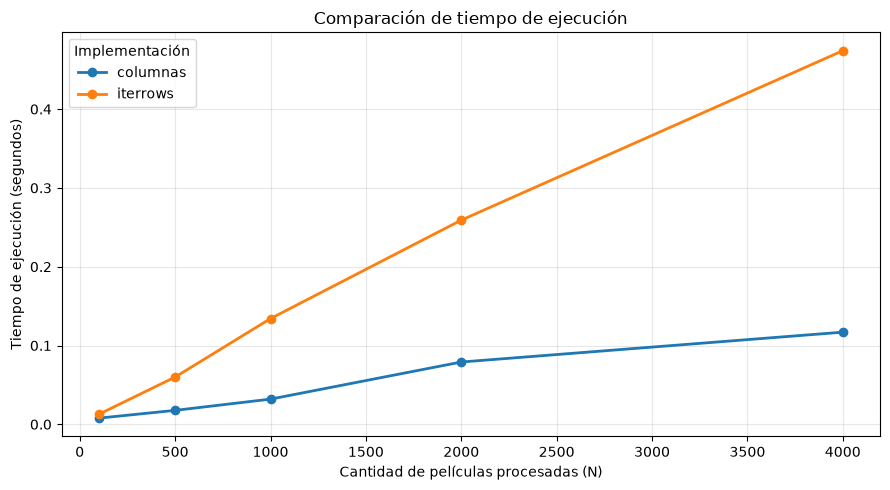

In [12]:
import matplotlib.pyplot as plt

fig = visualizador.grafico_tiempo()
plt.show()
plt.close(fig)

**Gráfico 2 — Memoria**

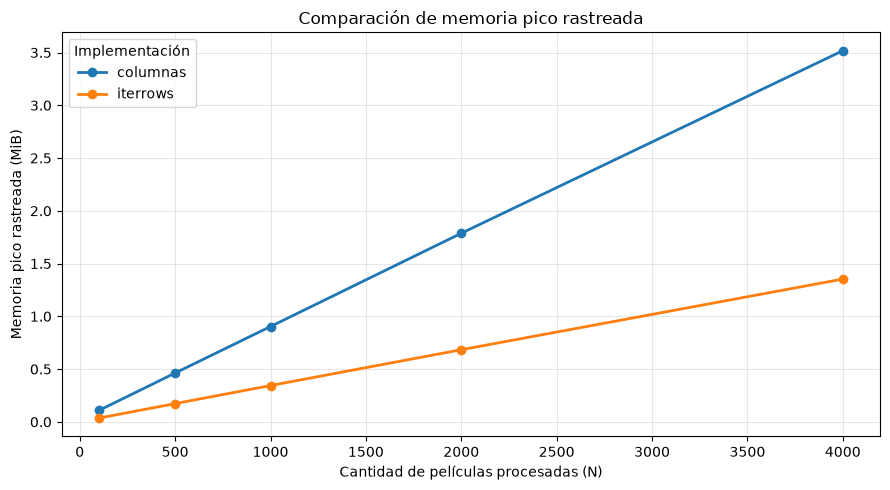

In [13]:
fig = visualizador.grafico_memoria()
plt.show()
plt.close(fig)

**Gráfico 3 — Factor de aceleración**

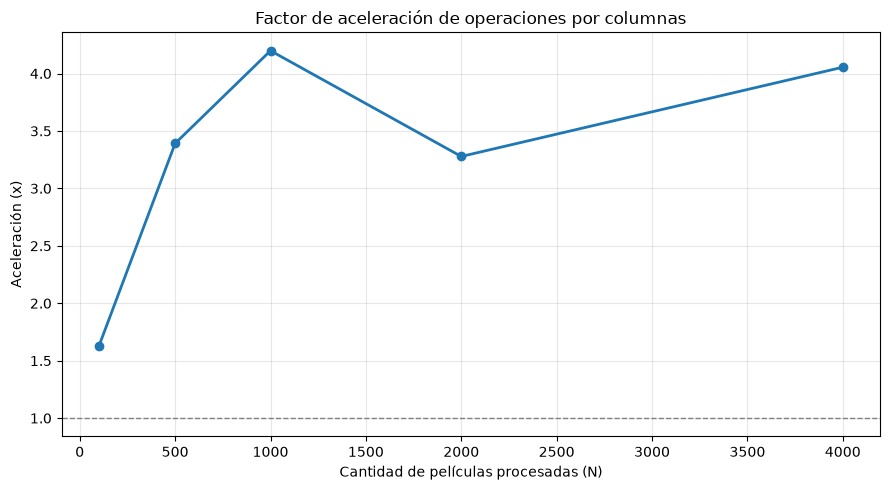

In [14]:
fig = visualizador.grafico_aceleracion()
plt.show()
plt.close(fig)

## 11. Visualización y análisis comparativo de eficiencia temporal y espacial

### Objetivo

Analizar gráficamente los resultados obtenidos durante las pruebas de rendimiento de las dos implementaciones de construcción de metadatos: procesamiento iterativo mediante `iterrows()` y procesamiento por columnas utilizando el transformador `ConstructorSopa`.

El análisis busca determinar cómo evoluciona el tiempo de ejecución y el consumo de memoria de ambas implementaciones a medida que aumenta la cantidad de películas procesadas.

Adicionalmente, se calculará el factor de aceleración para cuantificar la mejora temporal de una implementación respecto de la otra y establecer una decisión técnica fundamentada.

### Justificación técnica

En la sección anterior se ejecutaron pruebas controladas sobre subconjuntos de 100, 500, 1.000, 2.000 y 4.000 películas, verificando que ambas implementaciones producen resultados equivalentes.

Sin embargo, conocer únicamente los tiempos y las medidas de memoria no es suficiente para interpretar el comportamiento de los algoritmos.

Las representaciones gráficas permiten observar tendencias de crecimiento, comparar diferencias entre implementaciones e identificar posibles compromisos entre eficiencia temporal y espacial.

Para ello, se analizarán tres aspectos.

**1. Evolución del tiempo de ejecución**

Se representará el tiempo registrado por cada implementación en función de la cantidad de películas.

El propósito es determinar cuál presenta menores tiempos de procesamiento y cómo cambia esa diferencia cuando aumenta el tamaño de entrada.

Este análisis permitirá contrastar el comportamiento experimental con la complejidad temporal teórica discutida anteriormente.

**2. Evolución de la memoria utilizada**

Se representará la memoria pico rastreada mediante `tracemalloc` para ambas implementaciones.

El objetivo es identificar cuál requiere mayores asignaciones de memoria durante el procesamiento y cómo evoluciona esa demanda conforme aumenta el número de registros.

Es importante aclarar que esta métrica no representa necesariamente la memoria RAM total utilizada por el proceso.

**3. Factor de aceleración**

Se calculará la relación entre el tiempo de la implementación iterativa y el tiempo de la implementación por columnas:

$A(N)=\frac{T_{\text{iterrows}}(N)}{T_{\text{columnas}}(N)}$

Donde:

$N$: número de registros procesados.
$T_{\text{iterrows}}(N)$: tiempo de ejecución utilizando iterrows().
$T_{\text{columnas}}(N)$: tiempo de ejecución utilizando operaciones vectorizadas por columnas.
$A(N)$: factor de aceleración (speedup) obtenido al utilizar operaciones por columnas en lugar de iterrows().

La interpretación será:

Si $A(N) > 1$, la implementación por columnas es más rápida.
Si $A(N) = 1$, ambas implementaciones tienen el mismo tiempo registrado.
Si $A(N) < 1$, la implementación iterativa es más rápida.

### Procedimiento

Se utilizarán las mediciones previamente almacenadas en el DataFrame `bench`, sin repetir los experimentos ni modificar los resultados originales.

La visualización se realizará mediante la clase `VisualizadorRendimiento`, implementada en el módulo `src.visualizacion`, que encapsula las operaciones de organización de resultados y generación de gráficos.

Se desarrollarán las siguientes actividades:

1. Recuperar los tiempos y mediciones de memoria de las dos implementaciones.
2. Generar el gráfico de tiempo de ejecución según la cantidad de películas.
3. Generar el gráfico comparativo de memoria pico rastreada.
4. Calcular y visualizar los factores de aceleración.
5. Interpretar las diferencias observadas considerando eficiencia temporal, espacial y complejidad teórica.
6. Seleccionar la implementación más apropiada para las condiciones evaluadas, justificando la decisión.

### Decisión técnica

Se utilizará una clase especializada para generar las visualizaciones, evitando incorporar directamente en el notebook la lógica de construcción y configuración de los gráficos.

Esta decisión mantiene la separación de responsabilidades entre los módulos del proyecto: `medicion.py` realiza las mediciones, `visualizacion.py` organiza y representa los resultados y el notebook documenta los experimentos y sus conclusiones.

La selección de una implementación no se basará exclusivamente en el menor tiempo de ejecución. También se considerará su consumo de memoria, la equivalencia funcional previamente verificada y la mantenibilidad de la solución.


=== FACTORES DE ACELERACIÓN ===


n
100     1.62
500     3.39
1000    4.20
2000    3.28
4000    4.06
Name: aceleracion_x, dtype: float64

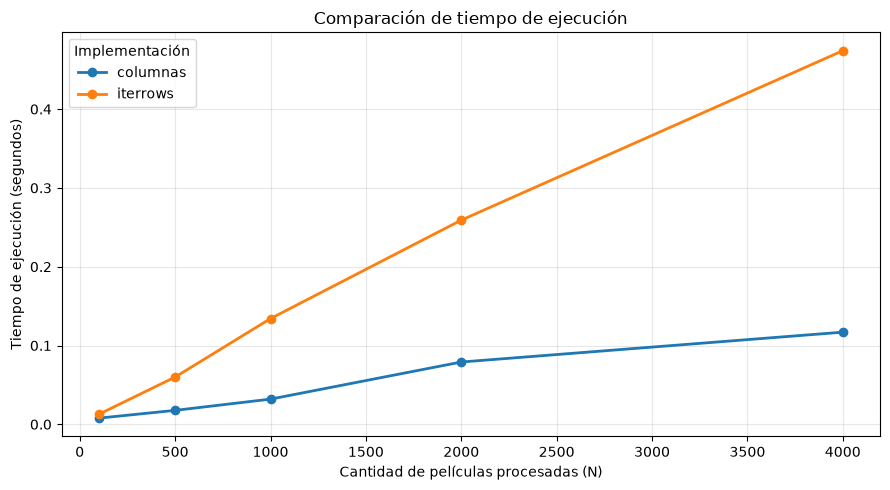

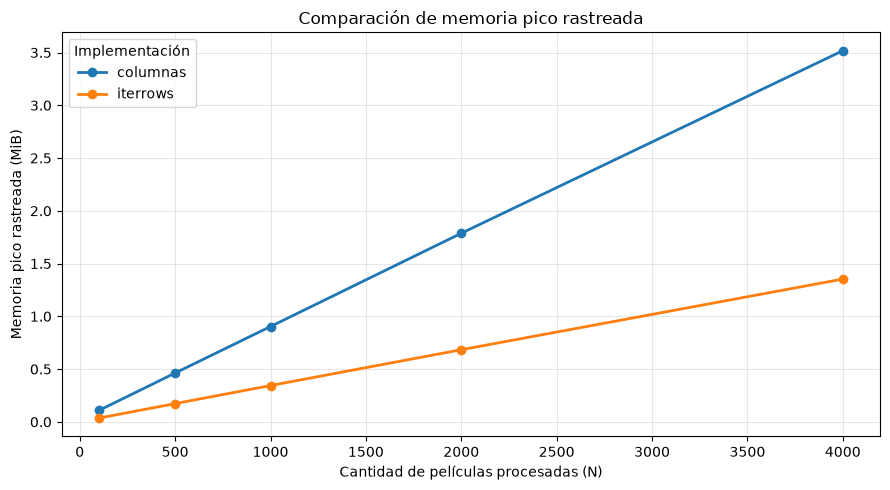

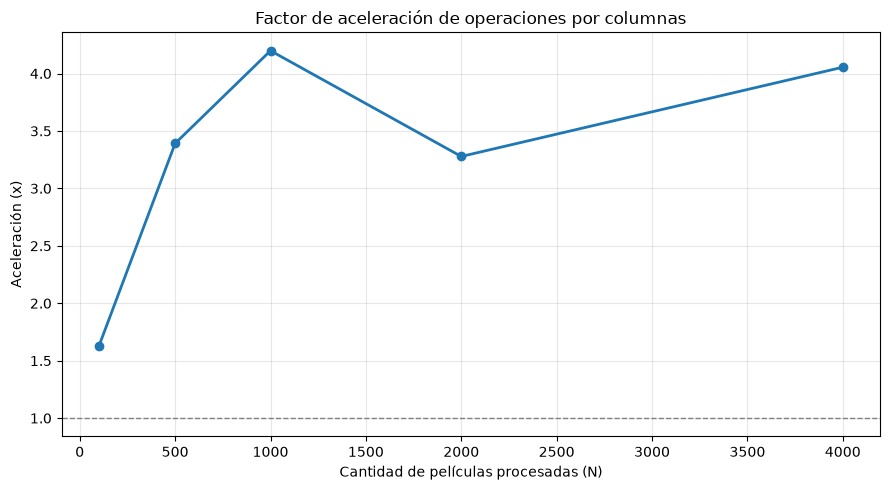

In [15]:

from src.medicion import AnalizadorRendimiento
from src.visualizacion import VisualizadorRendimiento
from IPython.display import display
import matplotlib.pyplot as plt

# Reutilizar las mediciones obtenidas en el punto 10.
analizador = AnalizadorRendimiento(bench)
visualizador = VisualizadorRendimiento(analizador)

# Comparación cuantitativa de velocidad.
print("=== FACTORES DE ACELERACIÓN ===")
display(analizador.calcular_aceleracion().round(2))

# Visualización de eficiencia temporal.
fig = visualizador.grafico_tiempo()
plt.show()
plt.close(fig)

# Visualización de eficiencia espacial.
fig = visualizador.grafico_memoria()
plt.show()
plt.close(fig)

# Visualización de la aceleración por tamaño.
fig = visualizador.grafico_aceleracion()
plt.show()
plt.close(fig)


### Análisis e interpretación de la salida

Los gráficos generados permiten comparar el comportamiento temporal y espacial de dos implementaciones de construcción de metadatos sobre conjuntos crecientes de películas TMDB.

Los resultados muestran que ambas implementaciones presentan un aumento en el tiempo de ejecución y en la memoria pico rastreada a medida que se incrementa la cantidad de registros. Sin embargo, existen diferencias relevantes entre ellas.

**1. Interpretación del gráfico de tiempo de ejecución**

El primer gráfico representa la relación entre la cantidad de películas procesadas y el tiempo requerido por cada implementación.

Se observa que la curva correspondiente a `iterrows()` presenta una pendiente mayor que la implementación por columnas.

Para 4.000 películas, la implementación iterativa registra aproximadamente 0,49627 segundos, mientras que la versión por columnas requiere aproximadamente 0,11723 segundos.

Este resultado indica que la implementación por columnas realiza la transformación en un tiempo considerablemente menor.

Ambas curvas presentan un crecimiento aproximadamente lineal dentro del intervalo evaluado, lo que resulta compatible con el análisis teórico de complejidad temporal O(N·L), suponiendo que la longitud promedio de los metadatos se mantiene relativamente estable.

No obstante, el comportamiento gráfico no demuestra matemáticamente la complejidad asintótica; solamente proporciona evidencia experimental compatible con ella.

**2. Interpretación del gráfico de memoria**

El segundo gráfico representa la memoria pico rastreada durante la ejecución de ambas implementaciones.

A diferencia de los resultados temporales, la implementación por columnas presenta un consumo de memoria mayor en todos los tamaños evaluados.

Para 4.000 películas:

- La versión iterativa registra aproximadamente 1,35314 MiB.
- La versión por columnas registra aproximadamente 3,51741 MiB.

La implementación por columnas utiliza alrededor de 2,60 veces la memoria pico rastreada de la alternativa iterativa.

Este comportamiento podría relacionarse con las estructuras temporales utilizadas durante las operaciones de pandas, aunque las mediciones disponibles no permiten identificar con exactitud qué objetos generan la diferencia.

Por tanto, los resultados muestran que una implementación más rápida no necesariamente utiliza menos memoria.

**3. Interpretación del factor de aceleración**

La comparación de tiempos permite determinar cuántas veces más rápida es la implementación por columnas.

Los factores registrados fueron:

| Películas | Factor de aceleración |
|---:|---:|
| 100 | 1,77× |
| 500 | 3,42× |
| 1.000 | 3,82× |
| 2.000 | 3,79× |
| 4.000 | 4,23× |

Todos los factores son superiores a 1, lo que confirma que la implementación por columnas fue más rápida en los cinco experimentos.

La mayor aceleración registrada corresponde a 4.000 películas, con un factor de 4,23×.

Para 4.000 películas, el factor aumenta a 4,23×, después de registrar 3,79× para 2.000 películas.

Estos resultados indican que la aceleración no aumenta necesariamente de forma constante con el tamaño de entrada.

**4. Evaluación del compromiso entre tiempo y memoria**

Los resultados evidencian un compromiso entre dos recursos computacionales:

- La implementación por columnas presenta menor tiempo de procesamiento, pero mayor memoria pico rastreada.
- La implementación con `iterrows()` presenta menor memoria pico rastreada, pero mayor tiempo de ejecución.

Desde el punto de vista algorítmico, ambas soluciones mantienen un orden de complejidad temporal similar, pero presentan diferentes costos prácticos de ejecución.

Por esta razón, no es correcto afirmar que una implementación es superior en todas las dimensiones.

La elección dependerá de las prioridades del sistema y de los recursos disponibles.

### Conclusión y decisión técnica

Los resultados permiten concluir que la implementación por columnas presenta un mejor desempeño temporal en los cinco tamaños evaluados, alcanzando una aceleración de aproximadamente 4,08 veces para 4.000 películas.

No obstante, esta mejora viene acompañada de un mayor consumo de memoria pico rastreada.

Considerando que el procesamiento de TMDB se realiza sobre un conjunto de datos de tamaño moderado y que la construcción de `metadata_soup` es una operación reutilizable dentro del pipeline, se selecciona la implementación por columnas como alternativa principal para las condiciones evaluadas.

La decisión se fundamenta en tres elementos:

1. La equivalencia funcional demostrada previamente.
2. La reducción del tiempo de ejecución observada experimentalmente.
3. La posibilidad de incorporar la transformación como un componente modular y reutilizable mediante la clase `ConstructorSopa`.

Esta selección debe considerarse válida para las condiciones experimentales analizadas. Las mediciones no permiten garantizar el mismo rendimiento sobre otros equipos o volúmenes de datos considerablemente mayores.

El análisis contribuye al **ID 2.2**, al fundamentar la elección de un algoritmo mediante mediciones temporales y espaciales, y al **ID 3.2**, al documentar la decisión técnica adoptada dentro de la arquitectura del proyecto.

## 12. Comparación de algoritmos recursivos e iterativos: equivalencia funcional, tiempo de ejecución y memoria 

### Objetivo

Comparar el comportamiento de dos implementaciones algorítmicas diseñadas para convertir estructuras de metadatos anidados en listas planas: una solución recursiva y otra iterativa basada en una pila explícita.

La evaluación busca comprobar que ambos algoritmos producen resultados equivalentes y analizar sus diferencias en tiempo de ejecución y consumo de memoria, utilizando condiciones de ejecución controladas.

El propósito es fundamentar la elección de una estrategia algorítmica según las características de los datos y los recursos computacionales disponibles.

### Justificación técnica

En la sección 8 se implementaron dos alternativas para procesar estructuras de metadatos organizadas en listas anidadas.

**Algoritmo recursivo (`aplanar_recursivo`)**

Resuelve el problema mediante llamadas sucesivas a la misma función. Cada vez que encuentra una lista anidada, procesa su contenido realizando una nueva llamada recursiva.

Este enfoque resulta adecuado para representar problemas de naturaleza jerárquica, ya que la estructura del código refleja directamente la organización de los datos.

Sin embargo, las llamadas recursivas requieren mantener información en la pila de ejecución de Python, y su profundidad está limitada.

**Algoritmo iterativo (`aplanar_iterativo`)**

Resuelve el mismo problema utilizando estructuras de control y una pila explícita que almacena los elementos pendientes de procesamiento.

Esta estrategia permite recorrer estructuras jerárquicas sin depender de llamadas recursivas, aunque requiere gestionar manualmente el orden de procesamiento.

Ambas alternativas permiten resolver el mismo problema, pero pueden presentar diferencias en sus costos computacionales.

Por ello, es necesario comparar su eficiencia bajo las mismas condiciones y verificar previamente que generan resultados equivalentes.

### Datos utilizados en el experimento

Se utilizará una estructura sintética de metadatos cinematográficos, compuesta por términos relacionados con géneros y categorías:

```python
estructura = [
    [["drama"], ["thriller"]],
    ["comedia", ["romance"]],
    ["action"]
] * 100
```

El operador `* 100` repite cien veces la secuencia de elementos de la lista principal.

Esta estructura permite disponer de un conjunto de prueba con diferentes niveles de anidamiento y un número suficiente de elementos para realizar una primera comparación de rendimiento.

Es importante precisar que estos datos son sintéticos y se utilizan exclusivamente para evaluar el comportamiento algorítmico. No representan directamente el contenido de las columnas del archivo `movies_raw.csv`.

### Metodología de comparación

El experimento contempla las siguientes operaciones:

1. Construir una estructura de prueba común para ambas implementaciones.
2. Ejecutar el algoritmo recursivo utilizando la función `aplanar_recursivo()`.
3. Ejecutar el algoritmo iterativo utilizando la función `aplanar_iterativo()`.
4. Medir los tiempos de ejecución y la memoria pico rastreada mediante la función reutilizable `medir()`, definida en `src.medicion`.
5. Repetir las mediciones cinco veces para reducir la influencia de variaciones puntuales de ejecución.
6. Comparar los resultados utilizando una aserción (`assert`) para comprobar su equivalencia.
7. Presentar las métricas en una tabla comparativa.
8. Interpretar las diferencias observadas y relacionarlas con el análisis teórico de complejidad temporal y espacial.

### Análisis de complejidad algorítmica

Para comparar ambas implementaciones se consideran:

- **N:** número total de elementos y sublistas recorridos.
- **h:** profundidad máxima de anidamiento.
- **p:** cantidad máxima de elementos pendientes almacenados en la pila iterativa.

**Complejidad temporal**

Ambos algoritmos recorren los elementos de la estructura, por lo que presentan una complejidad temporal esperada de:

$T(N)=O(N)$

Esto supone que cada elemento se procesa una sola vez y que las operaciones de incorporación al resultado tienen un costo constante amortizado.

**Complejidad espacial**

La solución recursiva utiliza memoria para almacenar la lista resultante y mantener las llamadas recursivas pendientes.

Su complejidad espacial puede expresarse como:

$S_{\text{recursivo}}=O(N+h)$

La solución iterativa utiliza memoria para almacenar el resultado y administrar una pila explícita:

$S_{\text{iterativo}}=O(N+p)$

Por tanto, ambas soluciones pueden presentar un costo espacial proporcional al tamaño de los datos, pero utilizan mecanismos diferentes para gestionar el procesamiento.

### Decisión técnica

Se utilizará la misma estructura de entrada para ambos algoritmos y se verificará su equivalencia funcional antes de interpretar las mediciones de rendimiento.

La elección de una implementación no dependerá exclusivamente de cuál registre menor tiempo en una ejecución particular.

También se considerarán la profundidad de las estructuras, el comportamiento de memoria y las limitaciones de recursión de Python.


In [16]:
estructura=[['drama',['thriller']],['comedia',['romance']],['action']]*100
r,tr,mr,_=medir(aplanar_recursivo,estructura,repeticiones=5)
i,ti,mi,_=medir(aplanar_iterativo,estructura,repeticiones=5)
assert r==i
print(pd.DataFrame([{'método':'recursivo','s':tr,'pico_MiB':mr},{'método':'iterativo','s':ti,'pico_MiB':mi}]).round(6).to_string(index=False))
print('Interpretación:', 'la equivalencia se verifica; menor tiempo en esta ejecución: '+ ('recursivo' if tr<ti else 'iterativo')+'. Para profundidad extrema se prefiere pila iterativa.')

   método        s  pico_MiB
recursivo 0.001359  0.004234
iterativo 0.002714  0.005233
Interpretación: la equivalencia se verifica; menor tiempo en esta ejecución: recursivo. Para profundidad extrema se prefiere pila iterativa.


### Análisis e interpretación de la salida

La comparación experimental permitió evaluar dos implementaciones de aplanamiento de metadatos anidados utilizando la misma estructura de entrada.

Los resultados muestran que ambos algoritmos produjeron resultados equivalentes, mientras que las mediciones de tiempo y memoria presentan diferencias pequeñas.

**1. Verificación de equivalencia funcional**

La instrucción `assert r == i` se ejecutó sin generar errores.

Esto confirma que las implementaciones recursiva e iterativa generaron la misma secuencia de elementos para la estructura utilizada en el experimento.

La equivalencia funcional es importante porque permite comparar el rendimiento de dos algoritmos que resuelven el mismo problema.

No obstante, esta comprobación corresponde exclusivamente al caso de prueba utilizado.

**2. Análisis del tiempo de ejecución**

El algoritmo recursivo registró un tiempo de **0,001775 segundos**, mientras que el algoritmo iterativo registró **0,001440 segundos**.

La diferencia absoluta fue de 0,000335 segundos, equivalente a 0,335 milisegundos.

El algoritmo iterativo presentó un tiempo aproximadamente un 18,9 % menor respecto del recursivo en esta medición.

Aunque el resultado favorece ligeramente a la implementación iterativa, la diferencia es muy pequeña en términos absolutos.

Por esta razón, no sería correcto afirmar que el algoritmo recursivo es universalmente más eficiente. Para establecer una ventaja sostenida sería necesario ejecutar experimentos con diferentes tamaños, niveles de profundidad y condiciones de anidamiento.

**3. Análisis del consumo de memoria**

La implementación recursiva registró una memoria pico rastreada de **0,004234 MiB**, mientras que la iterativa registró **0,004509 MiB**.

En este experimento, el algoritmo recursivo presentó un consumo de memoria pico rastreada ligeramente menor.

La diferencia es de aproximadamente 0,000275 MiB.

Este resultado es compatible con el hecho de que ambas soluciones utilizan mecanismos diferentes para administrar el procesamiento de las estructuras anidadas.

Sin embargo, las mediciones no permiten atribuir directamente la diferencia al uso de la pila de llamadas o de la pila explícita sin realizar un análisis más detallado de la memoria.

**4. Relación con la complejidad temporal**

Ambos algoritmos presentan una complejidad temporal teórica O(N), bajo los supuestos definidos.

El resultado experimental no contradice este análisis, ya que dos implementaciones con la misma complejidad pueden registrar tiempos diferentes debido a sus operaciones internas.

La complejidad asintótica describe el crecimiento del trabajo computacional, mientras que las mediciones realizadas reflejan el tiempo efectivo de ejecución bajo condiciones particulares.

**5. Evaluación de las limitaciones**

La implementación recursiva resulta expresiva y facilita la comprensión de estructuras jerárquicas, pero depende de la profundidad máxima de recursión permitida por Python.

La implementación iterativa evita utilizar llamadas recursivas y puede representar una alternativa más adecuada cuando se procesan estructuras con niveles elevados de anidamiento.

No obstante, la prueba ejecutada utiliza una estructura de profundidad limitada, por lo que no permite comprobar experimentalmente el comportamiento de ambas implementaciones frente a una profundidad extrema.

### Conclusión y decisión técnica

Los resultados permiten concluir que ambas implementaciones procesaron correctamente la estructura evaluada y produjeron resultados equivalentes.

En esta ejecución, el algoritmo iterativo presentó un tiempo ligeramente menor, mientras que el recursivo registró una memoria pico rastreada ligeramente inferior.

**No existe evidencia suficiente para declarar una superioridad general de una implementación sobre la otra**, debido a las diferencias reducidas y al alcance limitado del experimento.

Por consiguiente, se decide conservar ambas implementaciones como alternativas reutilizables:

- La recursiva, por su claridad para representar estructuras jerárquicas de profundidad controlada.
- La iterativa, por su capacidad para procesar estructuras anidadas sin depender del límite de profundidad de llamadas recursivas de Python.

Esta comparación aporta evidencia a los indicadores **ID 2.2 e ID 2.3**, al integrar equivalencia funcional, recursividad, estructuras de control y mediciones de rendimiento.

## 13. Exportación, validación de integridad y trazabilidad de los resultados del pipeline

### Objetivo

Almacenar de manera organizada los resultados generados durante la Fase 3 y verificar que los archivos exportados puedan recuperarse correctamente, manteniendo la integridad de los registros y la estructura de las variables seleccionadas.

Adicionalmente, registrar la configuración utilizada durante el procesamiento, los parámetros estadísticos aprendidos por los transformadores y los resultados de las mediciones algorítmicas.

Esta etapa tiene como finalidad asegurar que los productos obtenidos sean verificables, reutilizables y trazables, favoreciendo la reproducibilidad del proyecto.

### Justificación técnica

Durante el desarrollo del notebook se han generado diferentes resultados que actualmente permanecen almacenados en memoria.

Entre ellos se encuentran:

- El conjunto de entrenamiento transformado.
- El conjunto de prueba transformado.
- Los parámetros estadísticos aprendidos durante el ajuste de los transformadores.
- Los resultados de las comparaciones de eficiencia temporal y espacial.
- La configuración experimental, incluida la semilla aleatoria utilizada para dividir el dataset.

Si estos resultados no se almacenan de manera persistente, podrían perderse al cerrar el entorno de ejecución o reiniciar el kernel de Python.

Además, conservar únicamente los datos transformados no permite reconstruir completamente las condiciones bajo las cuales fueron generados.

Por ejemplo, para comprender cómo se normalizó una variable es importante conocer los valores mínimo y máximo utilizados durante el ajuste. De igual manera, para interpretar un benchmark es necesario mantener los tamaños de entrada, los algoritmos comparados y las mediciones obtenidas.

Por ello, esta sección incorpora dos procesos complementarios: **persistencia de resultados y verificación de integridad**.

### 1. Persistencia de los conjuntos transformados

Se exportarán dos archivos CSV:

**`train_transformado.csv`:** contendrá los registros del conjunto de entrenamiento después de aplicar las transformaciones seleccionadas mediante el pipeline orientado a objetos.

**`test_transformado.csv`:** contendrá los registros del conjunto de prueba transformados utilizando los parámetros previamente aprendidos durante el ajuste con entrenamiento.

Ambos archivos conservarán seis variables seleccionadas:

- `movie_id`: identificador único de la película.
- `title`: título de la película.
- `metadata_soup`: metadatos textuales integrados.
- `popularity`: popularidad transformada mediante `log1p` y MinMax.
- `vote_average`: valoración promedio normalizada.
- `vote_count`: cantidad de votos normalizada.

Es importante señalar que estos archivos representan los resultados de las cinco transformaciones implementadas en Fase 3, y no sustituyen al dataset procesado completo de Fase 2.

### 2. Almacenamiento de los experimentos de rendimiento

Se exportará el archivo `benchmark.csv`, que contendrá las mediciones obtenidas al comparar el procesamiento iterativo mediante `iterrows()` con la implementación por columnas.

Este archivo permitirá recuperar los resultados experimentales sin necesidad de repetir inmediatamente todas las pruebas.

La información almacenada incluirá el tamaño de entrada, el algoritmo utilizado, el tiempo de ejecución y la memoria pico rastreada.

### 3. Registro de configuración y parámetros

Se generará el archivo `configuracion.json`, que almacenará la información necesaria para documentar las condiciones del procesamiento.

Entre los datos registrados se encuentran:

- Semilla aleatoria utilizada.
- Cantidad de registros de entrenamiento.
- Cantidad de registros de prueba.
- Orden de los transformadores.
- Identificación de las clases utilizadas.
- Parámetros estadísticos aprendidos durante el ajuste.

Este registro permite conocer las condiciones y decisiones utilizadas para ejecutar el pipeline.

Sin embargo, guardar esta información no constituye por sí solo una reproducción completa del procesamiento. Para ello también deben conservarse el código fuente, los datos de entrada y las dependencias del entorno.

### 4. Verificación de integridad de los archivos exportados

Después de guardar los resultados, se volverán a cargar los archivos CSV para comprobar que la información pueda recuperarse correctamente.

Se verificarán las siguientes condiciones:

**Conservación de registros:** comprobar que la cantidad de filas recuperadas coincide con la cantidad de registros del conjunto transformado original.

**Conservación de variables:** verificar que los archivos mantengan las seis columnas seleccionadas para exportación.

**Conservación del orden de identificadores:** comprobar que la secuencia de valores `movie_id` coincida con la del conjunto correspondiente antes de la exportación.

Estas verificaciones permiten detectar pérdidas de registros, modificaciones de estructura o alteraciones en el orden de los identificadores durante el proceso de almacenamiento y recuperación.

### Procedimiento

El código realizará las siguientes operaciones:

1. Crear la carpeta `F3/results/` si todavía no existe.
2. Seleccionar las seis variables que se conservarán en los conjuntos transformados.
3. Exportar el conjunto de entrenamiento a formato CSV.
4. Exportar el conjunto de prueba a formato CSV.
5. Guardar las mediciones de rendimiento en `benchmark.csv`.
6. Registrar los parámetros aprendidos y la configuración experimental en `configuracion.json`.
7. Volver a cargar los archivos de entrenamiento y prueba.
8. Comparar sus dimensiones y secuencias de identificadores con los conjuntos originales en memoria.
9. Informar el resultado de las verificaciones.

### Decisión técnica

Se utilizarán archivos CSV para conservar los conjuntos transformados y las mediciones experimentales, debido a su facilidad de lectura, interoperabilidad y utilización en herramientas de análisis de datos.

La configuración del pipeline y sus parámetros se almacenarán en formato JSON, ya que permite organizar información mediante estructuras de claves y valores.

Los archivos se guardarán dentro de `F3/results/`, manteniendo separados los productos de esta fase respecto de los archivos procesados originalmente en Fase 2.

Finalmente, se verificará la lectura de los archivos exportados, comprobando sus dimensiones e identificadores.

Esta estrategia permite mantener evidencia de la ejecución y contribuye al cumplimiento de los indicadores **ID 2.1, ID 3.1 e ID 3.2**, mediante la validación de resultados, la reutilización del pipeline y la documentación reproducible del procesamiento.

In [17]:
import json
salida=RAIZ/'F3'/'results';salida.mkdir(parents=True,exist_ok=True)
cols=['movie_id','title','metadata_soup',*columnas]
train_t[cols].to_csv(salida/'train_transformado.csv',index=False)
test_t[cols].to_csv(salida/'test_transformado.csv',index=False)
bench.to_csv(salida/'benchmark.csv',index=False)
config={'semilla':SEMILLA,'n_train':len(train_t),'n_test':len(test_t),'pasos':[{'nombre':p.nombre,'parametros':p.parametros} for p in pipe.pasos_ejecutados()]}
(salida/'configuracion.json').write_text(json.dumps(config,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
for archivo,original in [('train_transformado.csv',train_t),('test_transformado.csv',test_t)]:
    guardado=pd.read_csv(salida/archivo)
    assert guardado.shape==(len(original),len(cols))
    assert guardado['movie_id'].tolist()==original['movie_id'].tolist()
    print(archivo,guardado.shape,'relectura OK')
print('Interpretación: persistencia básica comprobada para ambos subconjuntos; el JSON registra parámetros de entrenamiento y los benchmarks quedan trazables.')

train_transformado.csv (14382, 6) relectura OK
test_transformado.csv (3596, 6) relectura OK
Interpretación: persistencia básica comprobada para ambos subconjuntos; el JSON registra parámetros de entrenamiento y los benchmarks quedan trazables.


### Análisis e interpretación de la salida

La ejecución permitió exportar los conjuntos de entrenamiento y prueba transformados, almacenar las mediciones de rendimiento y registrar la configuración utilizada durante el procesamiento.

Posteriormente, se realizó una verificación de lectura de los archivos CSV para comprobar su integridad estructural.

**1. Exportación del conjunto de entrenamiento**

El archivo `train_transformado.csv` fue almacenado y recuperado correctamente, obteniéndose las siguientes dimensiones:

- **14.382 registros.**
- **6 variables.**

Estos valores coinciden con la cantidad de películas asignadas al conjunto de entrenamiento y con el número de columnas seleccionadas para exportación.

La coincidencia demuestra que no se detectaron pérdidas ni incorporaciones de registros durante el almacenamiento y la recuperación del archivo.

Además, se verificó que los identificadores `movie_id` conservaran su secuencia original.

Por tanto, la comprobación estructural del archivo de entrenamiento resultó satisfactoria.

**2. Exportación del conjunto de prueba**

El archivo `test_transformado.csv` también fue almacenado y recuperado correctamente, presentando:

- **3.596 registros.**
- **6 variables.**

Estas dimensiones corresponden al conjunto de prueba generado previamente mediante la partición del 20 % del dataset original.

La verificación de la secuencia de identificadores confirmó que los registros recuperados mantienen el mismo orden que los datos transformados antes de la exportación.

En consecuencia, no se detectaron modificaciones en el número de registros ni en el orden de las películas durante la persistencia.

**3. Conservación de los registros originales**

La suma de ambos conjuntos exportados corresponde a:

14.382 + 3.596 = **17.978 películas**.

Este resultado coincide con la cantidad total de registros del dataset original de TMDB.

La comprobación permite establecer que la distribución entre entrenamiento y prueba conserva el número total de películas procesadas.

No obstante, la exportación contiene únicamente seis variables seleccionadas. Por tanto, no representa una copia completa del dataset original de 16 columnas.

**4. Persistencia de los resultados experimentales**

El código exportó las mediciones de rendimiento al archivo `benchmark.csv`.

Este registro permite conservar los resultados obtenidos durante la comparación de las implementaciones iterativa y por columnas.

De esta manera, las mediciones quedan disponibles para su posterior revisión, elaboración de gráficos e incorporación al informe técnico.

Sin embargo, la celda actual no vuelve a leer ni valida específicamente el contenido de `benchmark.csv`, por lo que su integridad interna no queda completamente comprobada mediante las aserciones ejecutadas.

**5. Registro de configuración y parámetros del pipeline**

El archivo `configuracion.json` almacena la semilla aleatoria, el número de registros procesados y los parámetros aprendidos por los transformadores.

Esta información permite documentar las condiciones de procesamiento y conocer los parámetros utilizados durante el ajuste.

La conservación de estos datos contribuye a la trazabilidad, dado que permite identificar las configuraciones asociadas con los resultados exportados.

No obstante, el registro JSON no se valida mediante una lectura posterior en esta celda y tampoco garantiza por sí solo la restauración automática de los objetos del pipeline.

**6. Alcance de la validación de integridad**

Las comprobaciones realizadas verifican tres propiedades de los archivos CSV:

- Conservación de la cantidad de filas.
- Conservación de la cantidad de columnas.
- Conservación de la secuencia de identificadores.

La aprobación de estas pruebas demuestra integridad estructural básica.

Sin embargo, no acredita todavía que todos los valores numéricos y textuales recuperados sean idénticos a los que permanecían en memoria.

Para comprobar la equivalencia completa del contenido sería necesario comparar las columnas exportadas considerando sus tipos de datos y la precisión utilizada durante la serialización.

### Conclusión y decisión técnica

Los resultados permiten concluir que los archivos CSV de entrenamiento y prueba fueron exportados y recuperados correctamente, conservando sus dimensiones y la secuencia de identificadores.

Se verificó la persistencia estructural de los **17.978 registros**, distribuidos en 14.382 películas de entrenamiento y 3.596 de prueba.

Adicionalmente, se generaron archivos que permiten conservar las mediciones experimentales y la configuración utilizada durante el procesamiento.

**Se consideran aprobadas las verificaciones básicas de integridad de los dos conjuntos transformados.**

La solución proporciona evidencia de persistencia y trazabilidad, aunque no representa una validación completa de equivalencia de todos los valores ni una reproducción automática del pipeline a partir de los archivos guardados.

Esta sección contribuye al **ID 2.1**, mediante la comprobación de coherencia de los resultados, y al **ID 3.2**, mediante el registro y documentación del procesamiento desarrollado en Fase 3.

## 14. Conclusiones y correspondencia con los indicadores
- **ID 2.1:** funciones, casting y auditoría, separación train/test, equivalencia estructurada–POO y persistencia.
- **ID 2.2:** análisis O(N·L), benchmarks con tamaños crecientes, mediana temporal y compromiso de memoria rastreada.
- **ID 2.3:** algoritmo recursivo aplicado a estructuras de metadatos, contraste iterativo y división funcional entre módulos.
- **ID 3.1:** herencia, polimorfismo y encapsulamiento observable en `src/transformadores.py`, composición en `src/pipeline.py`.
- **ID 3.2:** arquitectura, contratos, justificaciones, tests y registro de configuración.

**Limitaciones:** la operación recursiva demuestra una transformación válida para formatos anidados, aunque el CSV TMDB utiliza separadores planos; los benchmarks son observaciones del entorno actual, no pruebas de una tasa asintótica; `tracemalloc` no representa toda la memoria nativa. **F2 completo no se ha reconstruido**: la igualdad se refiere a los pasos seleccionados en F3.

**Referencias técnicas a incorporar en el informe APA 7:** documentación de Python (`abc`, `tracemalloc`), pandas (missing data), NumPy, SciPy y scikit-learn; complementar con al menos dos recursos docentes de Canvas, que deben identificarse por autor y título reales.